In [11]:
import os, gc, math, random, warnings, json
from dataclasses import dataclass
from typing import Dict, Tuple, Optional

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
from tqdm.auto import tqdm
tqdm.pandas()

warnings.filterwarnings("ignore")
os.environ["TOKENIZERS_PARALLELISM"] = "false"

def seed_everything(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)

def tprint(msg):
    print(f"[INFO] {msg}", flush=True)

seed_everything(42)

@dataclass
class CFG:
    # ===== Data =====
    data_path: str = "belka_agg_downsampled.parquet"   # change if needed
    out_dir: str = "runs_mlm_hybrid_paper"
    smiles_col: str = "molecule_smiles"
    bb_cols: Tuple[str, str, str] = ("buildingblock1_smiles","buildingblock2_smiles","buildingblock3_smiles")
    targets: Tuple[str, str, str] = ("BRD4","HSA","sEH")

    # ===== Split =====
    split_mode: str = "bb_triplet"   # "bb_triplet" (leakage-safe) | "random"
    test_frac: float = 0.15
    val_frac: float = 0.15
    n_splits: int = 5

    # ===== Fingerprints =====
    fp_bits: int = 2048
    fp_radius: int = 2

    # ===== MLM (DAPT) =====
    do_mlm: bool = True
    base_model: str = "seyonec/ChemBERTa-zinc-base-v1"
    mlm_out: str = "ckpt_mlm_belka"
    mlm_max_len: int = 128
    mlm_prob: float = 0.15
    mlm_epochs: int = 1          # start with 1 for stability; increase later
    mlm_batch: int = 32
    mlm_lr: float = 5e-5
    mlm_sample_max: int = 1_000_000  # cap for stability; raise if you want

    # ===== Supervised hybrid =====
    max_len: int = 128
    batch_size: int = 32
    epochs_head: int = 1
    epochs_finetune: int = 3
    lr_head: float = 2e-3
    lr_encoder: float = 3e-5
    weight_decay: float = 0.01
    use_fp16: bool = True

    # ===== Anti-hallucination / safety =====
    lambda_promiscuity: float = 0.05      # regularizer discouraging over-predicting all 3
    target_precision: float = 0.90        # thresholding objective for deployment-like decoding

CFG = CFG()
os.makedirs(CFG.out_dir, exist_ok=True)
tprint(f"Output dir: {CFG.out_dir}")
print(CFG)


[INFO] Output dir: runs_mlm_hybrid_paper
CFG(data_path='belka_agg_downsampled.parquet', out_dir='runs_mlm_hybrid_paper', smiles_col='molecule_smiles', bb_cols=('buildingblock1_smiles', 'buildingblock2_smiles', 'buildingblock3_smiles'), targets=('BRD4', 'HSA', 'sEH'), split_mode='bb_triplet', test_frac=0.15, val_frac=0.15, n_splits=5, fp_bits=2048, fp_radius=2, do_mlm=True, base_model='seyonec/ChemBERTa-zinc-base-v1', mlm_out='ckpt_mlm_belka', mlm_max_len=128, mlm_prob=0.15, mlm_epochs=1, mlm_batch=32, mlm_lr=5e-05, mlm_sample_max=1000000, max_len=128, batch_size=32, epochs_head=1, epochs_finetune=3, lr_head=0.002, lr_encoder=3e-05, weight_decay=0.01, use_fp16=True, lambda_promiscuity=0.05, target_precision=0.9)


In [5]:
df = pd.read_parquet(CFG.data_path)
tprint(f"Loaded: {df.shape}")

need = [CFG.smiles_col, *CFG.bb_cols, *CFG.targets]
missing = [c for c in need if c not in df.columns]
if missing:
    raise ValueError(f"Missing columns: {missing}")

for t in CFG.targets:
    df[t] = df[t].astype(int)

df["y_combo"] = df[list(CFG.targets)].astype(str).agg("".join, axis=1)

tprint("Label combo (top 10):")
display(df["y_combo"].value_counts().head(10))


[INFO] Loaded: (1609779, 8)
[INFO] Label combo (top 10):


y_combo
001    644702
100    456070
010    328942
000    100000
011     79171
101       597
110       235
111        62
Name: count, dtype: int64

In [6]:
try:
    from rdkit import Chem
    from rdkit.Chem import AllChem
except Exception as e:
    raise RuntimeError(
        "RDKit is required for canonicalization and fingerprints. "
        "Install via conda-forge: conda install -c conda-forge rdkit"
    ) from e

def canon_smiles(s: str) -> str:
    try:
        m = Chem.MolFromSmiles(str(s))
        if m is None:
            return ""
        return Chem.MolToSmiles(m, isomericSmiles=True)
    except Exception:
        return ""

tprint("Canonicalizing SMILES (this may take a bit)...")
df[CFG.smiles_col] = df[CFG.smiles_col].astype(str).progress_map(canon_smiles)
for c in CFG.bb_cols:
    df[c] = df[c].astype(str).progress_map(canon_smiles)

before = len(df)
df = df[df[CFG.smiles_col].str.len() > 0].reset_index(drop=True)
tprint(f"Dropped invalid molecule SMILES: {before - len(df)} | Remaining: {len(df)}")

df["bb_triplet"] = df[CFG.bb_cols[0]] + "||" + df[CFG.bb_cols[1]] + "||" + df[CFG.bb_cols[2]]


[INFO] Canonicalizing SMILES (this may take a bit)...


100%|██████████| 1609779/1609779 [03:07<00:00, 8578.15it/s]


[INFO] Dropped invalid molecule SMILES: 0 | Remaining: 1609779


In [7]:
from sklearn.model_selection import train_test_split, StratifiedGroupKFold

def make_split(df_: pd.DataFrame):
    if CFG.split_mode == "random":
        tr, temp = train_test_split(
            df_, test_size=CFG.test_frac + CFG.val_frac,
            stratify=df_["y_combo"], random_state=42
        )
        rel = CFG.val_frac / (CFG.test_frac + CFG.val_frac)
        va, te = train_test_split(temp, test_size=1-rel, stratify=temp["y_combo"], random_state=43)
        return tr.reset_index(drop=True), va.reset_index(drop=True), te.reset_index(drop=True)

    sgkf = StratifiedGroupKFold(n_splits=CFG.n_splits, shuffle=True, random_state=42)
    folds = list(sgkf.split(df_, df_["y_combo"], groups=df_["bb_triplet"]))
    trval_idx, te_idx = folds[0]
    trval = df_.iloc[trval_idx].copy()
    te = df_.iloc[te_idx].copy()

    sgkf2 = StratifiedGroupKFold(n_splits=CFG.n_splits, shuffle=True, random_state=43)
    folds2 = list(sgkf2.split(trval, trval["y_combo"], groups=trval["bb_triplet"]))
    tr_idx, va_idx = folds2[0]
    tr = trval.iloc[tr_idx].copy()
    va = trval.iloc[va_idx].copy()

    overlap = len(set(tr["bb_triplet"]).intersection(set(te["bb_triplet"])))
    tprint(f"Group overlap(train,test) = {overlap} (should be 0)")
    return tr.reset_index(drop=True), va.reset_index(drop=True), te.reset_index(drop=True)

train_df, val_df, test_df = make_split(df)
tprint(f"Split sizes: train={len(train_df)} val={len(val_df)} test={len(test_df)}")

y_tr = train_df[list(CFG.targets)].values.astype(int)
y_va = val_df[list(CFG.targets)].values.astype(int)
y_te = test_df[list(CFG.targets)].values.astype(int)


[INFO] Group overlap(train,test) = 0 (should be 0)
[INFO] Split sizes: train=1030258 val=257565 test=321956


In [8]:
def build_bb_vocab(train_df_: pd.DataFrame) -> Dict[str,int]:
    bbs = pd.concat([train_df_[c].astype(str) for c in CFG.bb_cols]).unique().tolist()
    vocab = {"[PAD]": 0, "[UNK]": 1}
    for b in bbs:
        if b not in vocab:
            vocab[b] = len(vocab)
    return vocab

bb_vocab = build_bb_vocab(train_df)
bb_pad = bb_vocab["[PAD]"]
bb_unk = bb_vocab["[UNK]"]
inv_bb = {v:k for k,v in bb_vocab.items()}

tprint(f"BB vocab size: {len(bb_vocab)}")

def encode_bb(df_: pd.DataFrame) -> np.ndarray:
    arr = np.zeros((len(df_), 3), dtype=np.int64)
    for i,(b1,b2,b3) in enumerate(zip(df_[CFG.bb_cols[0]], df_[CFG.bb_cols[1]], df_[CFG.bb_cols[2]])):
        arr[i,0] = bb_vocab.get(str(b1), bb_unk)
        arr[i,1] = bb_vocab.get(str(b2), bb_unk)
        arr[i,2] = bb_vocab.get(str(b3), bb_unk)
    return arr

bb_tr = encode_bb(train_df)
bb_va = encode_bb(val_df)
bb_te = encode_bb(test_df)


[INFO] BB vocab size: 1147


In [9]:
def fp_to_packed(smiles: str) -> np.ndarray:
    m = Chem.MolFromSmiles(smiles)
    if m is None:
        bits = np.zeros(CFG.fp_bits, dtype=np.uint8)
    else:
        bv = AllChem.GetMorganFingerprintAsBitVect(m, CFG.fp_radius, nBits=CFG.fp_bits)
        bits = np.asarray(bv, dtype=np.uint8)
    return np.packbits(bits)  # length fp_bits/8

def build_fp_memmap(df_: pd.DataFrame, name: str) -> str:
    path = os.path.join(CFG.out_dir, f"{name}_fp_packed.npy")
    if os.path.exists(path):
        tprint(f"FP exists: {path}")
        return path

    n = len(df_)
    pack_len = (CFG.fp_bits + 7) // 8
    mm = np.lib.format.open_memmap(path, mode="w+", dtype=np.uint8, shape=(n, pack_len))

    tprint(f"Building fingerprints: {name} (n={n})")
    for i, smi in enumerate(tqdm(df_[CFG.smiles_col].values, desc=f"FP[{name}]", smoothing=0.05)):
        mm[i] = fp_to_packed(str(smi))
        if (i+1) % 200_000 == 0:
            mm.flush()

    del mm
    tprint(f"Saved FP: {path}")
    return path

fp_tr_path = build_fp_memmap(train_df, "train")
fp_va_path = build_fp_memmap(val_df, "val")
fp_te_path = build_fp_memmap(test_df, "test")


[INFO] Building fingerprints: train (n=1030258)


FP[train]: 100%|██████████| 1030258/1030258 [14:27<00:00, 1187.82it/s]

[INFO] Saved FP: runs_mlm_hybrid_paper\train_fp_packed.npy
[INFO] Building fingerprints: val (n=257565)



FP[val]: 100%|██████████| 257565/257565 [03:43<00:00, 1150.79it/s]

[INFO] Saved FP: runs_mlm_hybrid_paper\val_fp_packed.npy
[INFO] Building fingerprints: test (n=321956)



FP[test]: 100%|██████████| 321956/321956 [04:36<00:00, 1163.89it/s]

[INFO] Saved FP: runs_mlm_hybrid_paper\test_fp_packed.npy


In [13]:
import torch
from torch.utils.data import Dataset
from transformers import (
    AutoTokenizer, AutoModelForMaskedLM,
    DataCollatorForLanguageModeling,
    Trainer, TrainingArguments
)

mlm_tokenizer = AutoTokenizer.from_pretrained(CFG.base_model)

class SmilesMLMDataset(Dataset):
    def __init__(self, smiles_list, tokenizer, max_len=128):
        self.smiles = [str(s) for s in smiles_list]
        self.tok = tokenizer
        self.max_len = max_len

    def __len__(self):
        return len(self.smiles)

    def __getitem__(self, idx):
        return self.tok(
            self.smiles[idx],
            truncation=True,
            max_length=self.max_len,
            return_special_tokens_mask=True
        )

train_smiles = train_df[CFG.smiles_col].values
if len(train_smiles) > CFG.mlm_sample_max:
    tprint(f"MLM cap: sampling {CFG.mlm_sample_max} of {len(train_smiles)} train SMILES")
    idx = np.random.RandomState(42).choice(len(train_smiles), CFG.mlm_sample_max, replace=False)
    train_smiles = train_smiles[idx]

mlm_train_ds = SmilesMLMDataset(train_smiles, mlm_tokenizer, CFG.mlm_max_len)
mlm_val_ds = SmilesMLMDataset(val_df[CFG.smiles_col].values[:100_000], mlm_tokenizer, CFG.mlm_max_len)

collator = DataCollatorForLanguageModeling(
    tokenizer=mlm_tokenizer,
    mlm=True,
    mlm_probability=CFG.mlm_prob
)

tprint(f"MLM train size: {len(mlm_train_ds)} | MLM val size: {len(mlm_val_ds)}")


[INFO] MLM cap: sampling 1000000 of 1030258 train SMILES
[INFO] MLM train size: 1000000 | MLM val size: 100000


In [17]:
import transformers, inspect
from transformers import TrainingArguments

print("transformers version:", transformers.__version__)
sig = inspect.signature(TrainingArguments.__init__).parameters
print("Has evaluation_strategy?", "evaluation_strategy" in sig)
print("Has eval_strategy?", "eval_strategy" in sig)
print("Has evaluate_during_training?", "evaluate_during_training" in sig)
print("Has do_eval?", "do_eval" in sig)
print("Has save_strategy?", "save_strategy" in sig)
print("Has disable_tqdm?", "disable_tqdm" in sig)


transformers version: 4.51.3
Has evaluation_strategy? False
Has eval_strategy? True
Has evaluate_during_training? False
Has do_eval? True
Has save_strategy? True
Has disable_tqdm? True


In [18]:
from transformers import AutoModelForMaskedLM, Trainer, TrainingArguments
import os, torch

tprint("Starting MLM continued pretraining (Trainer progress bar enabled)...")

mlm_model = AutoModelForMaskedLM.from_pretrained(CFG.base_model)

args = TrainingArguments(
    output_dir=os.path.join(CFG.out_dir, CFG.mlm_out),
    overwrite_output_dir=True,
    per_device_train_batch_size=CFG.mlm_batch,
    per_device_eval_batch_size=CFG.mlm_batch,
    num_train_epochs=CFG.mlm_epochs,
    learning_rate=CFG.mlm_lr,
    weight_decay=CFG.weight_decay,

    # ✅ correct name for your version:
    eval_strategy="epoch",
    save_strategy="epoch",
    save_total_limit=2,
    load_best_model_at_end=True,
    metric_for_best_model="eval_loss",

    fp16=(CFG.use_fp16 and torch.cuda.is_available()),
    report_to="none",
    dataloader_num_workers=0,     # Windows stability
    logging_strategy="steps",
    logging_steps=50,
    disable_tqdm=False,           # ✅ keep progress bars
)

trainer = Trainer(
    model=mlm_model,
    args=args,
    train_dataset=mlm_train_ds,
    eval_dataset=mlm_val_ds,
    data_collator=collator,
    tokenizer=mlm_tokenizer,
)

trainer.train()

mlm_ckpt = os.path.join(CFG.out_dir, CFG.mlm_out)
trainer.save_model(mlm_ckpt)
mlm_tokenizer.save_pretrained(mlm_ckpt)
tprint(f"Saved MLM checkpoint: {mlm_ckpt}")


[INFO] Starting MLM continued pretraining (Trainer progress bar enabled)...


Some weights of the model checkpoint at seyonec/ChemBERTa-zinc-base-v1 were not used when initializing RobertaForMaskedLM: ['roberta.pooler.dense.bias', 'roberta.pooler.dense.weight']
- This IS expected if you are initializing RobertaForMaskedLM from the checkpoint of a model trained on another task or with another architecture (e.g. initializing a BertForSequenceClassification model from a BertForPreTraining model).
- This IS NOT expected if you are initializing RobertaForMaskedLM from the checkpoint of a model that you expect to be exactly identical (initializing a BertForSequenceClassification model from a BertForSequenceClassification model).


Epoch,Training Loss,Validation Loss
1,0.045000,0.038939


There were missing keys in the checkpoint model loaded: ['lm_head.decoder.weight', 'lm_head.decoder.bias'].


[INFO] Saved MLM checkpoint: runs_mlm_hybrid_paper\ckpt_mlm_belka


In [19]:
import torch.nn as nn
from torch.utils.data import DataLoader
from transformers import AutoModel, AutoTokenizer, get_cosine_schedule_with_warmup

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
tprint(f"Device: {device}")

downstream_model = mlm_ckpt if CFG.do_mlm else CFG.base_model
tok = AutoTokenizer.from_pretrained(downstream_model)
enc = AutoModel.from_pretrained(downstream_model)


[INFO] Device: cuda


Some weights of RobertaModel were not initialized from the model checkpoint at runs_mlm_hybrid_paper\ckpt_mlm_belka and are newly initialized: ['pooler.dense.bias', 'pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


In [20]:
class BelkaDataset(torch.utils.data.Dataset):
    def __init__(self, df_, fp_path, bb_arr, y=None):
        self.df = df_
        self.fp = np.load(fp_path, mmap_mode="r")  # packed uint8 memmap
        self.bb = bb_arr
        self.y = None if y is None else y.astype(np.float32)

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        smi = str(self.df.iloc[idx][CFG.smiles_col])
        out = tok(smi, truncation=True, max_length=CFG.max_len)
        item = {
            "input_ids": out["input_ids"],
            "attention_mask": out["attention_mask"],
            "fp_packed": self.fp[idx],     # (fp_bits/8,)
            "bb_ids": self.bb[idx],        # (3,)
        }
        if self.y is not None:
            item["labels"] = self.y[idx]
        return item

def collate(batch):
    ids = [torch.tensor(b["input_ids"], dtype=torch.long) for b in batch]
    am  = [torch.tensor(b["attention_mask"], dtype=torch.long) for b in batch]
    ids = nn.utils.rnn.pad_sequence(ids, batch_first=True, padding_value=tok.pad_token_id)
    am  = nn.utils.rnn.pad_sequence(am,  batch_first=True, padding_value=0)

    fp_packed = np.stack([b["fp_packed"] for b in batch])  # (B, 256)
    fp_bits = np.unpackbits(fp_packed, axis=1)[:, :CFG.fp_bits].astype(np.float32)  # (B, 2048)
    fp_bits = torch.tensor(fp_bits, dtype=torch.float32)

    bb_ids = torch.tensor(np.stack([b["bb_ids"] for b in batch]), dtype=torch.long)

    out = {"input_ids": ids, "attention_mask": am, "fp_bits": fp_bits, "bb_ids": bb_ids}
    if "labels" in batch[0]:
        out["labels"] = torch.tensor(np.stack([b["labels"] for b in batch]), dtype=torch.float32)
    return out

ds_tr = BelkaDataset(train_df, fp_tr_path, bb_tr, y_tr)
ds_va = BelkaDataset(val_df,   fp_va_path, bb_va, y_va)
ds_te = BelkaDataset(test_df,  fp_te_path, bb_te, y_te)

dl_tr = DataLoader(ds_tr, batch_size=CFG.batch_size, shuffle=True,  num_workers=0, collate_fn=collate)
dl_va = DataLoader(ds_va, batch_size=CFG.batch_size, shuffle=False, num_workers=0, collate_fn=collate)
dl_te = DataLoader(ds_te, batch_size=CFG.batch_size, shuffle=False, num_workers=0, collate_fn=collate)

tprint("Dataloaders ready.")


[INFO] Dataloaders ready.


In [21]:
class MeanAttnPool(nn.Module):
    def __init__(self, hidden):
        super().__init__()
        self.attn = nn.Linear(hidden, 1)

    def forward(self, h, mask):
        maskf = mask.unsqueeze(-1).float()
        mean = (h * maskf).sum(1) / torch.clamp(maskf.sum(1), min=1.0)

        scores = self.attn(h).squeeze(-1)
        scores = scores.masked_fill(mask == 0, -1e4)
        w = torch.softmax(scores, dim=1).unsqueeze(-1)
        attn = (h * w).sum(1)

        return torch.cat([mean, attn], dim=1)  # (B, 2H)


In [22]:
class MLMHybridMultiLabel(nn.Module):
    def __init__(self, encoder, bb_vocab_size, fp_dim, n_targets):
        super().__init__()
        self.encoder = encoder
        H = self.encoder.config.hidden_size
        self.pool = MeanAttnPool(H)

        self.bb_emb = nn.Embedding(bb_vocab_size, 64, padding_idx=bb_pad)
        self.bb_proj = nn.Sequential(
            nn.Linear(64, 128),
            nn.ReLU(),
            nn.Dropout(0.1)
        )

        self.fp_proj = nn.Sequential(
            nn.Linear(fp_dim, 512),
            nn.ReLU(),
            nn.Dropout(0.1),
            nn.Linear(512, 256),
            nn.ReLU(),
            nn.Dropout(0.1)
        )

        fusion_in = 2*H + 128 + 256
        self.head = nn.Sequential(
            nn.LayerNorm(fusion_in),
            nn.Dropout(0.2),
            nn.Linear(fusion_in, 512),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(512, n_targets)
        )

    def forward(self, input_ids, attention_mask, fp_bits, bb_ids):
        out = self.encoder(input_ids=input_ids, attention_mask=attention_mask)
        h = out.last_hidden_state
        pooled = self.pool(h, attention_mask)

        bb = self.bb_emb(bb_ids).mean(1)
        bb = self.bb_proj(bb)

        fp = self.fp_proj(fp_bits)

        fused = torch.cat([pooled, bb, fp], dim=1)
        logits = self.head(fused)
        return logits, fused

model = MLMHybridMultiLabel(enc, bb_vocab_size=len(bb_vocab), fp_dim=CFG.fp_bits, n_targets=len(CFG.targets)).to(device)
tprint(f"Model params (M): {sum(p.numel() for p in model.parameters())/1e6:.2f}")


[INFO] Model params (M): 46.36


In [23]:
import torch

def make_pos_weight(y):
    pos = y.sum(0).astype(np.float32)
    neg = (len(y) - pos).astype(np.float32)
    w = np.clip(neg / np.clip(pos, 1.0, None), 1.0, 100.0)
    return torch.tensor(w, dtype=torch.float32, device=device)

pos_weight = make_pos_weight(y_tr)
bce = nn.BCEWithLogitsLoss(pos_weight=pos_weight)

def loss_fn(logits, targets):
    base = bce(logits, targets)
    p = torch.sigmoid(logits)
    reg = ((p.sum(1) - targets.sum(1))**2).mean()
    return base + CFG.lambda_promiscuity * reg


In [24]:
def freeze_all_encoder(m):
    for p in m.encoder.parameters():
        p.requires_grad = False

def unfreeze_last_k_layers(m, k=2):
    # Try common transformer layouts
    freeze_all_encoder(m)
    candidates = []
    if hasattr(m.encoder, "encoder") and hasattr(m.encoder.encoder, "layer"):
        candidates = list(m.encoder.encoder.layer)
    elif hasattr(m.encoder, "roberta") and hasattr(m.encoder.roberta, "encoder") and hasattr(m.encoder.roberta.encoder, "layer"):
        candidates = list(m.encoder.roberta.encoder.layer)
    elif hasattr(m.encoder, "encoder") and hasattr(m.encoder, "layer"):
        candidates = list(m.encoder.layer)

    if candidates:
        for layer in candidates[-k:]:
            for p in layer.parameters():
                p.requires_grad = True
        return

    # fallback: unfreeze everything
    for p in m.encoder.parameters():
        p.requires_grad = True


In [25]:
from sklearn.metrics import average_precision_score

@torch.no_grad()
def predict_probs_and_fused(dl, desc="infer"):
    model.eval()
    probs_all, fused_all, logits_all = [], [], []
    for batch in tqdm(dl, desc=desc, leave=False, smoothing=0.05):
        logits, fused = model(
            batch["input_ids"].to(device),
            batch["attention_mask"].to(device),
            batch["fp_bits"].to(device),
            batch["bb_ids"].to(device),
        )
        probs_all.append(torch.sigmoid(logits).float().cpu().numpy())
        fused_all.append(fused.float().cpu().numpy())
        logits_all.append(logits.float().cpu().numpy())
    return (
        np.concatenate(probs_all, 0),
        np.concatenate(fused_all, 0),
        np.concatenate(logits_all, 0),
    )

def train_phase(epochs, lr_head, lr_enc, unfreeze_k: int, phase_name: str):
    if unfreeze_k == 0:
        freeze_all_encoder(model)
    else:
        unfreeze_last_k_layers(model, k=unfreeze_k)

    head_params, enc_params = [], []
    for n,p in model.named_parameters():
        if not p.requires_grad:
            continue
        if n.startswith("encoder."):
            enc_params.append(p)
        else:
            head_params.append(p)

    opt = torch.optim.AdamW(
        [{"params": head_params, "lr": lr_head},
         {"params": enc_params,  "lr": lr_enc}],
        weight_decay=CFG.weight_decay
    )

    total_steps = len(dl_tr) * epochs
    warmup = int(0.08 * total_steps)
    sched = get_cosine_schedule_with_warmup(opt, warmup, total_steps)

    scaler = torch.cuda.amp.GradScaler(enabled=(CFG.use_fp16 and device.type == "cuda"))

    best = -1.0
    best_state = None

    tprint(f"=== {phase_name} ===")
    for ep in range(1, epochs+1):
        model.train()
        losses = []

        pbar = tqdm(dl_tr, desc=f"{phase_name} | ep {ep}/{epochs}", smoothing=0.05)
        for batch in pbar:
            opt.zero_grad(set_to_none=True)

            x  = batch["input_ids"].to(device)
            am = batch["attention_mask"].to(device)
            fp = batch["fp_bits"].to(device)
            bb = batch["bb_ids"].to(device)
            y  = batch["labels"].to(device)

            with torch.cuda.amp.autocast(enabled=(CFG.use_fp16 and device.type == "cuda")):
                logits, _ = model(x, am, fp, bb)
                loss = loss_fn(logits, y)

            scaler.scale(loss).backward()
            scaler.step(opt)
            scaler.update()
            sched.step()

            losses.append(float(loss.detach().cpu()))
            if len(losses) >= 20:
                pbar.set_postfix(loss=float(np.mean(losses[-20:])))

        va_prob, _, _ = predict_probs_and_fused(dl_va, desc=f"{phase_name} | val")
        va_micro = average_precision_score(y_va, va_prob, average="micro")
        tprint(f"{phase_name} ep{ep}: train_loss={np.mean(losses):.4f} | val micro-AP={va_micro:.4f}")

        if va_micro > best:
            best = va_micro
            best_state = {k: v.detach().cpu().clone() for k,v in model.state_dict().items()}

    if best_state is not None:
        model.load_state_dict(best_state, strict=True)

    tprint(f"{phase_name} best val micro-AP: {best:.4f}")
    return best

best_a = train_phase(CFG.epochs_head, lr_head=CFG.lr_head,    lr_enc=0.0,           unfreeze_k=0, phase_name="Phase A (head)")
best_b = train_phase(CFG.epochs_finetune, lr_head=CFG.lr_head/3, lr_enc=CFG.lr_encoder, unfreeze_k=2, phase_name="Phase B (finetune last2)")
tprint(f"Best val micro-AP (final): {best_b:.4f}")


[INFO] === Phase A (head) ===


Phase A (head) | ep 1/1: 100%|██████████| 32196/32196 [17:59<00:00, 29.84it/s, loss=0.228]


[INFO] Phase A (head) ep1: train_loss=0.2474 | val micro-AP=0.9686
[INFO] Phase A (head) best val micro-AP: 0.9686
[INFO] === Phase B (finetune last2) ===


Phase B (finetune last2) | ep 1/3: 100%|██████████| 32196/32196 [28:40<00:00, 18.71it/s, loss=0.2]  


[INFO] Phase B (finetune last2) ep1: train_loss=0.2154 | val micro-AP=0.9694


Phase B (finetune last2) | ep 2/3: 100%|██████████| 32196/32196 [28:38<00:00, 18.73it/s, loss=0.185]


[INFO] Phase B (finetune last2) ep2: train_loss=0.2045 | val micro-AP=0.9717


Phase B (finetune last2) | ep 3/3: 100%|██████████| 32196/32196 [28:40<00:00, 18.71it/s, loss=0.177]


[INFO] Phase B (finetune last2) ep3: train_loss=0.1901 | val micro-AP=0.9719
[INFO] Phase B (finetune last2) best val micro-AP: 0.9719
[INFO] Best val micro-AP (final): 0.9719


In [26]:
te_prob, te_fused, te_logits = predict_probs_and_fused(dl_te, desc="TEST inference")
tprint(f"Test inference done. prob shape={te_prob.shape}, fused shape={te_fused.shape}")


[INFO] Test inference done. prob shape=(321956, 3), fused shape=(321956, 1920)


[INFO] Test metrics:
{'micro_AP': 0.9718330266682799, 'macro_AP': 0.9523763321606394, 'AP_BRD4': 0.9891050116220093, 'AP_HSA': 0.881281572861517, 'AP_sEH': 0.9867424119983917}


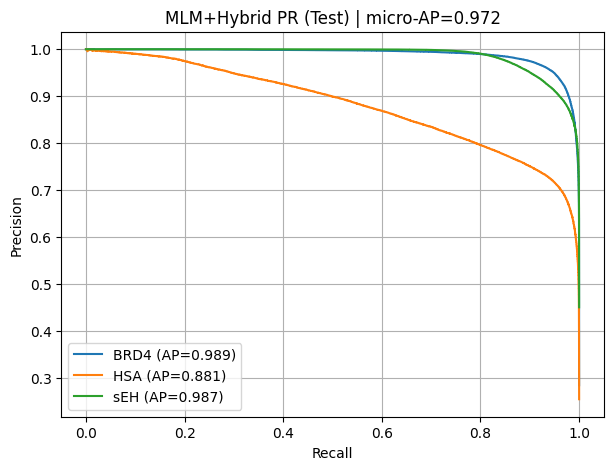

In [27]:
from sklearn.metrics import precision_recall_curve, average_precision_score

def multilabel_ap(y_true, y_prob):
    out = {
        "micro_AP": float(average_precision_score(y_true, y_prob, average="micro")),
        "macro_AP": float(average_precision_score(y_true, y_prob, average="macro")),
    }
    for i,t in enumerate(CFG.targets):
        out[f"AP_{t}"] = float(average_precision_score(y_true[:, i], y_prob[:, i]))
    return out

def plot_pr(y_true, y_prob, title):
    plt.figure(figsize=(7,5))
    for i,t in enumerate(CFG.targets):
        p,r,_ = precision_recall_curve(y_true[:, i], y_prob[:, i])
        ap = average_precision_score(y_true[:, i], y_prob[:, i])
        plt.plot(r, p, label=f"{t} (AP={ap:.3f})")
    micro = average_precision_score(y_true, y_prob, average="micro")
    plt.title(f"{title} | micro-AP={micro:.3f}")
    plt.xlabel("Recall"); plt.ylabel("Precision")
    plt.grid(True); plt.legend()
    plt.show()

tprint("Test metrics:")
print(multilabel_ap(y_te, te_prob))
plot_pr(y_te, te_prob, "MLM+Hybrid PR (Test)")


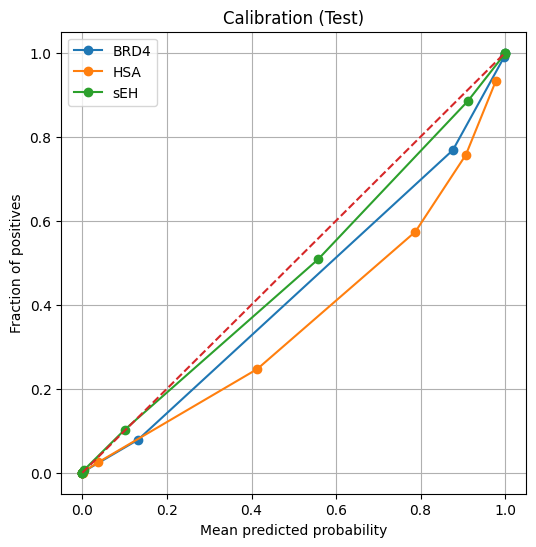

In [28]:
from sklearn.calibration import calibration_curve

def plot_calibration(y_true, y_prob, title, bins=10):
    plt.figure(figsize=(6,6))
    for i,t in enumerate(CFG.targets):
        frac_pos, mean_pred = calibration_curve(y_true[:, i], y_prob[:, i], n_bins=bins, strategy="quantile")
        plt.plot(mean_pred, frac_pos, marker="o", label=t)
    plt.plot([0,1],[0,1], linestyle="--")
    plt.xlabel("Mean predicted probability")
    plt.ylabel("Fraction of positives")
    plt.title(title)
    plt.grid(True); plt.legend()
    plt.show()

plot_calibration(y_te, te_prob, "Calibration (Test)")


[INFO] Hallucination report @0.5: {'gt_triple': 8, 'pred_triple': 18, 'triple_when_gt<=1': 8, 'pred_zero': 12378}


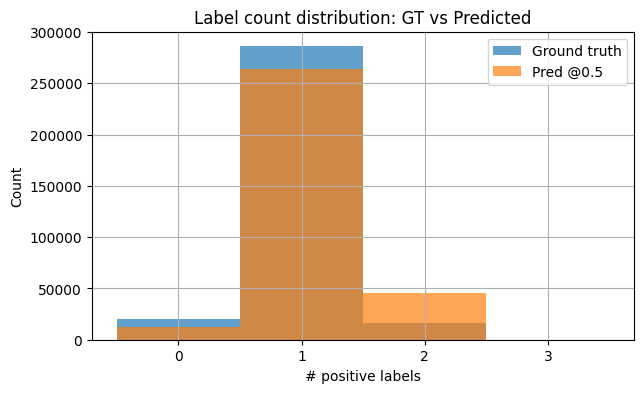

In [29]:
def hallucination_report(y_true, prob, thr=0.5):
    pred = (prob >= thr).astype(int)
    gt_cnt = y_true.sum(1)
    pr_cnt = pred.sum(1)
    return {
        "gt_triple": int((gt_cnt==3).sum()),
        "pred_triple": int((pr_cnt==3).sum()),
        "triple_when_gt<=1": int(((gt_cnt<=1) & (pr_cnt==3)).sum()),
        "pred_zero": int((pr_cnt==0).sum()),
    }

rep = hallucination_report(y_te, te_prob, thr=0.5)
tprint(f"Hallucination report @0.5: {rep}")

plt.figure(figsize=(7,4))
plt.hist(y_te.sum(1), bins=[-0.5,0.5,1.5,2.5,3.5], alpha=0.7, label="Ground truth")
plt.hist((te_prob>=0.5).sum(1), bins=[-0.5,0.5,1.5,2.5,3.5], alpha=0.7, label="Pred @0.5")
plt.xticks([0,1,2,3])
plt.xlabel("# positive labels")
plt.ylabel("Count")
plt.title("Label count distribution: GT vs Predicted")
plt.grid(True); plt.legend()
plt.show()


[INFO] Fitting per-target temperature scaling (grid search)...
[INFO] T[BRD4] = 1.259 (best NLL=0.08266)
[INFO] T[HSA] = 1.413 (best NLL=0.22798)
[INFO] T[sEH] = 1.122 (best NLL=0.13355)
[INFO] Metrics after temp scaling (test):
{'micro_AP': 0.97215494898203, 'macro_AP': 0.9523763976720862, 'AP_BRD4': 0.9891051284364432, 'AP_HSA': 0.8812815810118908, 'AP_sEH': 0.9867424835679246}


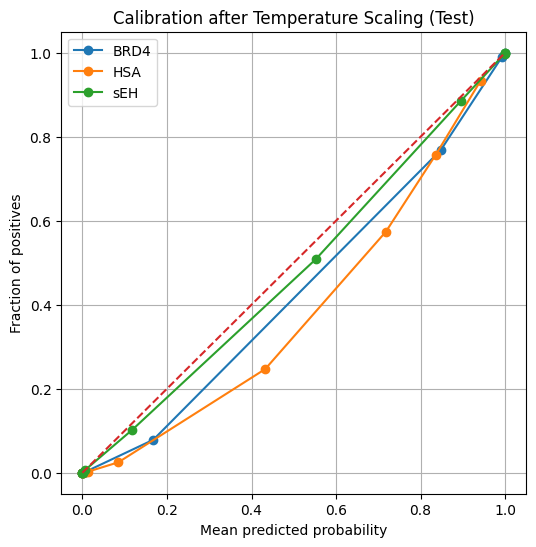

In [30]:
# We grid-search T to minimize NLL per label on VAL logits
va_prob, _, va_logits = predict_probs_and_fused(dl_va, desc="VAL logits for temp-scaling")

def nll_from_logits(logits, y, T):
    z = logits / T
    p = 1.0 / (1.0 + np.exp(-z))
    eps = 1e-9
    return -np.mean(y*np.log(p+eps) + (1-y)*np.log(1-p+eps))

T_grid = np.logspace(-1, 1, 41)  # 0.1 .. 10
temps = np.ones(len(CFG.targets), dtype=np.float32)

tprint("Fitting per-target temperature scaling (grid search)...")
for i,t in enumerate(CFG.targets):
    best = (1e18, 1.0)
    for T in T_grid:
        loss = nll_from_logits(va_logits[:, i], y_va[:, i], T)
        if loss < best[0]:
            best = (loss, T)
    temps[i] = best[1]
    tprint(f"T[{t}] = {temps[i]:.3f} (best NLL={best[0]:.5f})")

def apply_temp(logits, temps):
    p = []
    for i in range(logits.shape[1]):
        z = logits[:, i] / temps[i]
        p.append(1.0 / (1.0 + np.exp(-z)))
    return np.stack(p, axis=1).astype(np.float32)

te_prob_cal = apply_temp(te_logits, temps)
tprint("Metrics after temp scaling (test):")
print(multilabel_ap(y_te, te_prob_cal))
plot_calibration(y_te, te_prob_cal, "Calibration after Temperature Scaling (Test)")


In [31]:
from sklearn.metrics import precision_score, recall_score, f1_score

def find_threshold_for_precision(y_true, y_prob, target_precision=0.9):
    # Search thresholds from high to low -> first meeting precision, with max recall
    thr_grid = np.linspace(0.99, 0.01, 99)
    best = None
    for thr in thr_grid:
        pred = (y_prob >= thr).astype(int)
        if pred.sum() == 0:
            continue
        prec = precision_score(y_true, pred, zero_division=0)
        rec = recall_score(y_true, pred, zero_division=0)
        if prec >= target_precision:
            if best is None or rec > best["rec"]:
                best = {"thr": thr, "prec": prec, "rec": rec}
    # if impossible, fall back to 0.5
    if best is None:
        return 0.5
    return float(best["thr"])

# Use CALIBRATED probs on VAL to set thresholds
va_prob_cal = apply_temp(va_logits, temps)

thresholds = np.zeros(len(CFG.targets), dtype=np.float32)
for i,t in enumerate(CFG.targets):
    thresholds[i] = find_threshold_for_precision(y_va[:, i], va_prob_cal[:, i], CFG.target_precision)
    tprint(f"thr[{t}]={thresholds[i]:.3f} (target precision={CFG.target_precision})")

def decode(prob, thresholds):
    return (prob >= thresholds.reshape(1,-1)).astype(int)

te_pred_safe = decode(te_prob_cal, thresholds)

# report “hallucination” under safe decoding
gt_cnt = y_te.sum(1)
pr_cnt = te_pred_safe.sum(1)
safe_rep = {
    "pred_triple": int((pr_cnt==3).sum()),
    "triple_when_gt<=1": int(((gt_cnt<=1) & (pr_cnt==3)).sum()),
    "pred_zero": int((pr_cnt==0).sum()),
}
tprint(f"SAFE decoding report: {safe_rep}")

# quick per-target precision/recall
for i,t in enumerate(CFG.targets):
    prec = precision_score(y_te[:, i], te_pred_safe[:, i], zero_division=0)
    rec  = recall_score(y_te[:, i], te_pred_safe[:, i], zero_division=0)
    f1   = f1_score(y_te[:, i], te_pred_safe[:, i], zero_division=0)
    print(f"{t}: precision={prec:.3f} recall={rec:.3f} f1={f1:.3f}")


[INFO] thr[BRD4]=0.380 (target precision=0.9)
[INFO] thr[HSA]=0.850 (target precision=0.9)
[INFO] thr[sEH]=0.450 (target precision=0.9)
[INFO] SAFE decoding report: {'pred_triple': 7, 'triple_when_gt<=1': 1, 'pred_zero': 33504}
BRD4: precision=0.901 recall=0.978 f1=0.938
HSA: precision=0.902 recall=0.492 f1=0.637
sEH: precision=0.901 recall=0.959 f1=0.929


In [32]:
from scipy.stats import spearmanr

# If scipy is not installed, install it:
# !pip -q install scipy
# If you prefer no scipy, tell me and I'll replace spearman with numpy rank-corr.

def bb_lift_table(df_, bb_arr, prob, position: int, min_count=200):
    """
    For each BB id at a given position:
      - count
      - GT positive rate per target
      - Pred mean probability per target
      - GT lift = P(y=1|BB)/P(y=1)
      - Pred lift = meanP_BB / overall_meanP
    """
    ids = bb_arr[:, position]
    uniq = np.unique(ids)

    overall_gt = df_[list(CFG.targets)].values.mean(0)
    overall_pr = prob.mean(0)

    rows = []
    for bb_id in tqdm(uniq, desc=f"BB lift pos{position+1}", smoothing=0.05):
        mask = (ids == bb_id)
        n = int(mask.sum())
        if n < min_count:
            continue

        gt = df_.iloc[mask][list(CFG.targets)].values.mean(0)
        pr = prob[mask].mean(0)

        gt_lift = gt / np.clip(overall_gt, 1e-9, None)
        pr_lift = pr / np.clip(overall_pr, 1e-9, None)

        rows.append([int(bb_id), inv_bb.get(int(bb_id), ""), n,
                     *gt.tolist(), *pr.tolist(),
                     *gt_lift.tolist(), *pr_lift.tolist()])

    cols = (
        ["bb_id","bb_smiles","count"] +
        [f"gt_rate_{t}" for t in CFG.targets] +
        [f"pred_meanP_{t}" for t in CFG.targets] +
        [f"gt_lift_{t}" for t in CFG.targets] +
        [f"pred_lift_{t}" for t in CFG.targets]
    )
    return pd.DataFrame(rows, columns=cols)

# Use calibrated probs for analysis
tab_bb1 = bb_lift_table(test_df, bb_te, te_prob_cal, position=0, min_count=200)
tab_bb2 = bb_lift_table(test_df, bb_te, te_prob_cal, position=1, min_count=200)
tab_bb3 = bb_lift_table(test_df, bb_te, te_prob_cal, position=2, min_count=200)

tprint("Example table (BB1):")
display(tab_bb1.head(5))


BB lift pos3: 100%|██████████| 872/872 [00:00<00:00, 878.03it/s] 

[INFO] Example table (BB1):


,bb_id,bb_smiles,count,gt_rate_BRD4,gt_rate_HSA,gt_rate_sEH,pred_meanP_BRD4,pred_meanP_HSA,pred_meanP_sEH,gt_lift_BRD4,gt_lift_HSA,gt_lift_sEH,pred_lift_BRD4,pred_lift_HSA,pred_lift_sEH
0,2,C#CC[C@H](CC(=O)O)NC(=O)OCC1c2ccccc2-c2ccccc21,543,0.270718,0.318600,0.337017,0.296492,0.364139,0.359643,0.953917,1.254682,0.749061,0.983357,1.202328,0.787082
1,3,C#CC[C@H](NC(=O)OCC1c2ccccc2-c2ccccc21)C(=O)O,716,0.322626,0.396648,0.268156,0.333663,0.474857,0.266432,1.136820,1.562042,0.596011,1.106642,1.567902,0.583090
2,4,CC(C)(C)OCC(NC(=O)OCC1c2ccccc2-c2ccccc21)C(=O)O,3718,0.655460,0.214094,0.178591,0.679346,0.292406,0.180629,2.309612,0.843124,0.396940,2.253149,0.965477,0.395309
3,5,CC(C)CC(NC(=O)OCC1c2ccccc2-c2ccccc21)C(=O)O,7073,0.802488,0.117489,0.111268,0.822716,0.173989,0.112737,2.827689,0.462684,0.247307,2.728653,0.574482,0.246727
4,6,COc1ccc(C(=O)O)c(NC(=O)OCC2c3ccccc3-c3ccccc32)c1,868,0.206221,0.538018,0.233871,0.236245,0.611262,0.245668,0.726652,2.118774,0.519807,0.783541,2.018287,0.537646


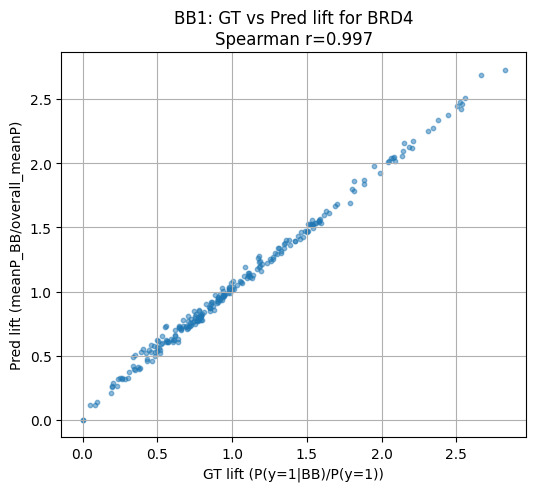

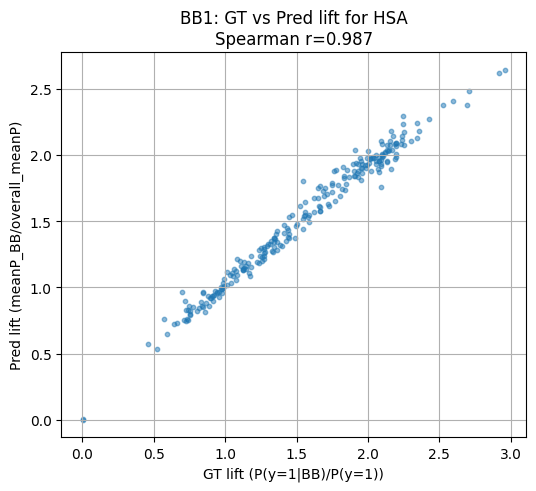

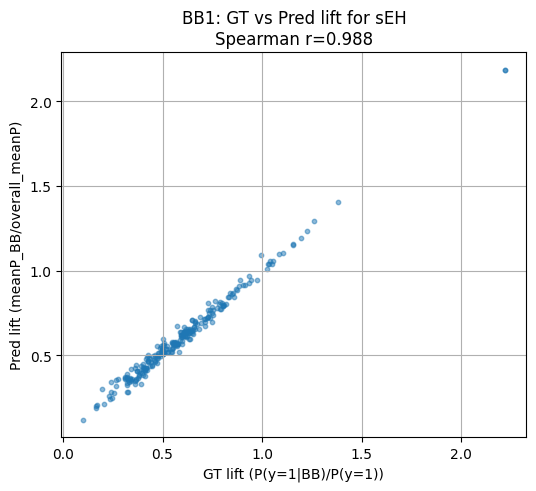

In [42]:
def plot_lift_scatter(tab, target: str, title: str):
    x = tab[f"gt_lift_{target}"].values
    y = tab[f"pred_lift_{target}"].values
    r = spearmanr(x, y).correlation

    plt.figure(figsize=(6,5))
    plt.scatter(x, y, s=10, alpha=0.5)
    plt.xlabel("GT lift (P(y=1|BB)/P(y=1))")
    plt.ylabel("Pred lift (meanP_BB/overall_meanP)")
    plt.title(f"{title}\nSpearman r={r:.3f}")
    plt.grid(True)
    plt.show()

for t in CFG.targets:
    plot_lift_scatter(tab_bb1, t, f"BB1: GT vs Pred lift for {t}")


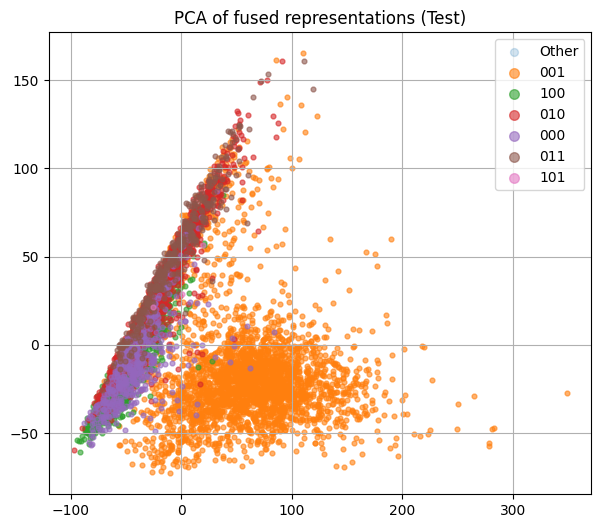

In [43]:
from sklearn.decomposition import PCA

# Subsample for speed
N = len(te_fused)
max_n = 8000
if N > max_n:
    idx = np.random.RandomState(42).choice(N, max_n, replace=False)
    X = te_fused[idx]
    combo = test_df.iloc[idx]["y_combo"].values
else:
    X = te_fused
    combo = test_df["y_combo"].values

pca = PCA(n_components=2, random_state=42)
xy = pca.fit_transform(X)

common = pd.Series(combo).value_counts().head(6).index.tolist()
mask_common = np.array([c in common for c in combo])

plt.figure(figsize=(7,6))
plt.scatter(xy[~mask_common,0], xy[~mask_common,1], s=8, alpha=0.2, label="Other")
for c in common:
    m = (combo == c)
    plt.scatter(xy[m,0], xy[m,1], s=12, alpha=0.6, label=c)
plt.title("PCA of fused representations (Test)")
plt.grid(True); plt.legend(markerscale=2)
plt.show()


[INFO] t-SNE uses 5000 points (subsampled) for speed.
[INFO] Running t-SNE (can take time)...


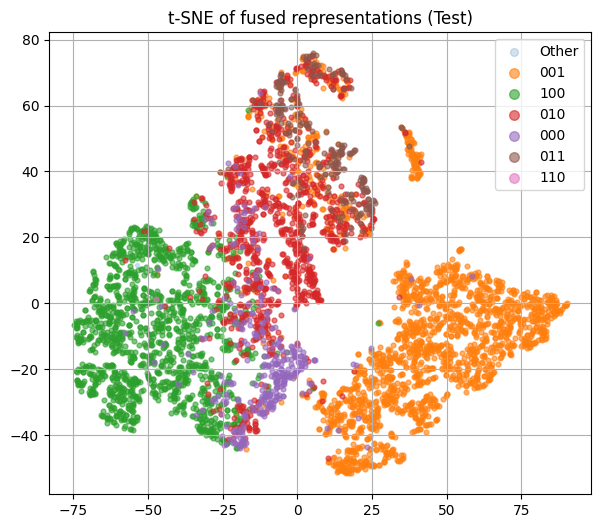

In [44]:
from sklearn.manifold import TSNE

max_tsne = 5000
if len(X) > max_tsne:
    tprint(f"t-SNE uses {max_tsne} points (subsampled) for speed.")
    idx2 = np.random.RandomState(7).choice(len(X), max_tsne, replace=False)
    X_tsne = X[idx2]
    combo_tsne = combo[idx2]
else:
    X_tsne = X
    combo_tsne = combo

tprint("Running t-SNE (can take time)...")
tsne = TSNE(n_components=2, perplexity=30, init="pca", learning_rate="auto", random_state=42)
xy2 = tsne.fit_transform(X_tsne)

common = pd.Series(combo_tsne).value_counts().head(6).index.tolist()
mask_common = np.array([c in common for c in combo_tsne])

plt.figure(figsize=(7,6))
plt.scatter(xy2[~mask_common,0], xy2[~mask_common,1], s=8, alpha=0.2, label="Other")
for c in common:
    m = (combo_tsne == c)
    plt.scatter(xy2[m,0], xy2[m,1], s=12, alpha=0.6, label=c)
plt.title("t-SNE of fused representations (Test)")
plt.grid(True); plt.legend(markerscale=2)
plt.show()


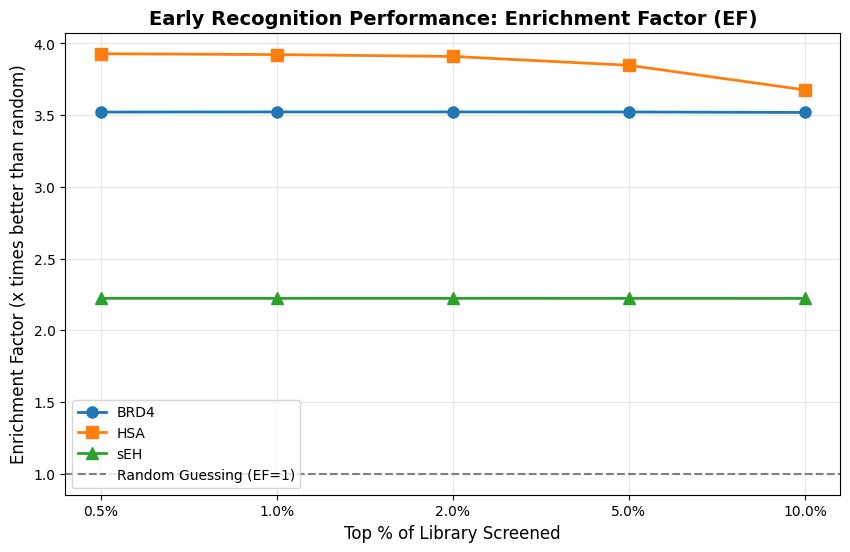

Interpretation: An EF of 10 at 1% means the top 1% of your list contains 10x more active drugs than a random selection.


In [45]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

def calculate_enrichment_factor(y_true, y_prob, fractions=[0.005, 0.01, 0.02, 0.05, 0.1]):
    """Calculates Enrichment Factor (EF) at various fractions."""
    results = {}
    for i, target in enumerate(CFG.targets):
        # Sort by score descending
        df_temp = pd.DataFrame({'true': y_true[:, i], 'prob': y_prob[:, i]})
        df_temp = df_temp.sort_values('prob', ascending=False)
        
        n_total = len(df_temp)
        n_actives = df_temp['true'].sum()
        base_rate = n_actives / n_total
        
        target_efs = []
        for frac in fractions:
            top_n = int(n_total * frac)
            if top_n == 0: top_n = 1
            
            # Count actives in top n
            top_actives = df_temp.iloc[:top_n]['true'].sum()
            precision = top_actives / top_n
            
            # EF = Precision / Base Rate
            ef = precision / base_rate if base_rate > 0 else 0
            target_efs.append(ef)
        results[target] = target_efs
    return results, fractions

# --- PLOTTING ---
ef_data, x_fracs = calculate_enrichment_factor(y_te, te_prob)
x_labels = [f'{x*100}%' for x in x_fracs]

plt.figure(figsize=(10, 6))
markers = ['o', 's', '^']
colors = ['#1f77b4', '#ff7f0e', '#2ca02c']

for i, target in enumerate(CFG.targets):
    plt.plot(x_labels, ef_data[target], marker=markers[i], lw=2, markersize=8, 
             color=colors[i], label=f'{target}')

plt.axhline(1, color='gray', linestyle='--', label='Random Guessing (EF=1)')
plt.title('Early Recognition Performance: Enrichment Factor (EF)', fontsize=14, fontweight='bold')
plt.ylabel('Enrichment Factor (x times better than random)', fontsize=12)
plt.xlabel('Top % of Library Screened', fontsize=12)
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

print("Interpretation: An EF of 10 at 1% means the top 1% of your list contains 10x more active drugs than a random selection.")

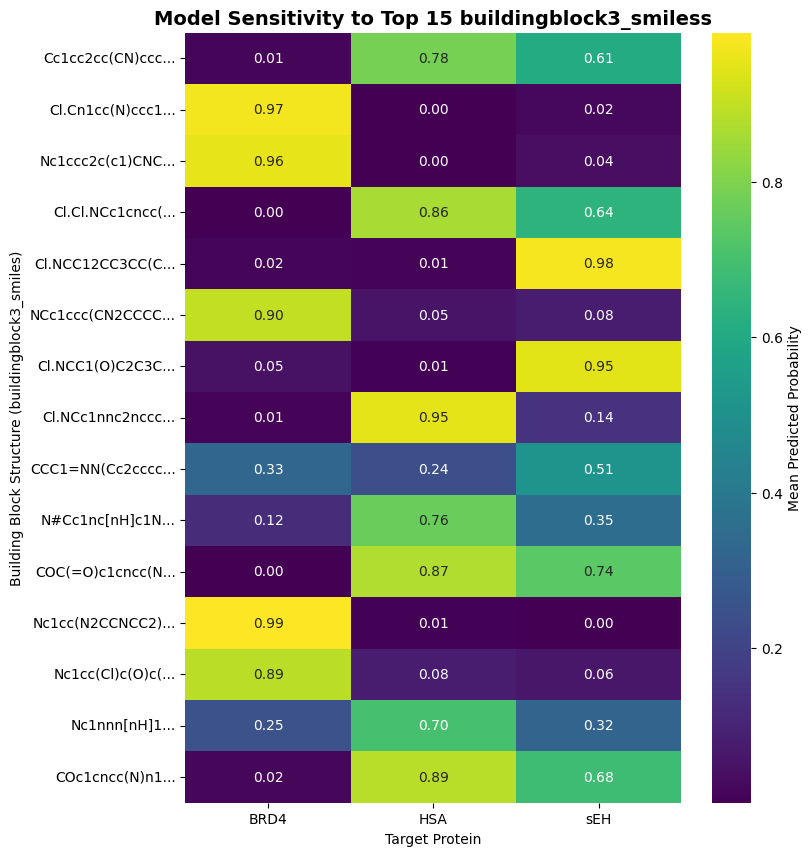

In [46]:
import seaborn as sns

def plot_bb_bias_heatmap(test_df, y_prob, targets, bb_col='buildingblock3_smiles', top_n=15):
    """
    Analyzes model predictions per building block to check for bias.
    """
    # Create a temp dataframe with predictions
    df_res = test_df.copy()
    for i, t in enumerate(targets):
        df_res[f'pred_{t}'] = y_prob[:, i]
    
    # Get top N most frequent building blocks in test set
    top_bbs = df_res[bb_col].value_counts().head(top_n).index
    
    # Calculate mean prediction for these blocks
    heatmap_data = []
    y_labels = []
    
    for bb in top_bbs:
        # Shorten SMILES for display (take first 10 chars)
        short_name = bb[:15] + "..." 
        y_labels.append(short_name)
        
        row_data = []
        subset = df_res[df_res[bb_col] == bb]
        for t in targets:
            mean_pred = subset[f'pred_{t}'].mean()
            row_data.append(mean_pred)
        heatmap_data.append(row_data)
        
    heatmap_data = np.array(heatmap_data)
    
    # Plot
    plt.figure(figsize=(8, 10))
    sns.heatmap(heatmap_data, annot=True, cmap='viridis', fmt='.2f', 
                xticklabels=targets, yticklabels=y_labels, cbar_kws={'label': 'Mean Predicted Probability'})
    
    plt.title(f'Model Sensitivity to Top {top_n} {bb_col}s', fontsize=14, fontweight='bold')
    plt.xlabel('Target Protein')
    plt.ylabel(f'Building Block Structure ({bb_col})')
    plt.show()

# Run for BB3 (often the variable component in DEL libraries)
# Ensure test_df is available (from the split step in your notebook)
plot_bb_bias_heatmap(test_df, te_prob, CFG.targets, bb_col='buildingblock3_smiles')

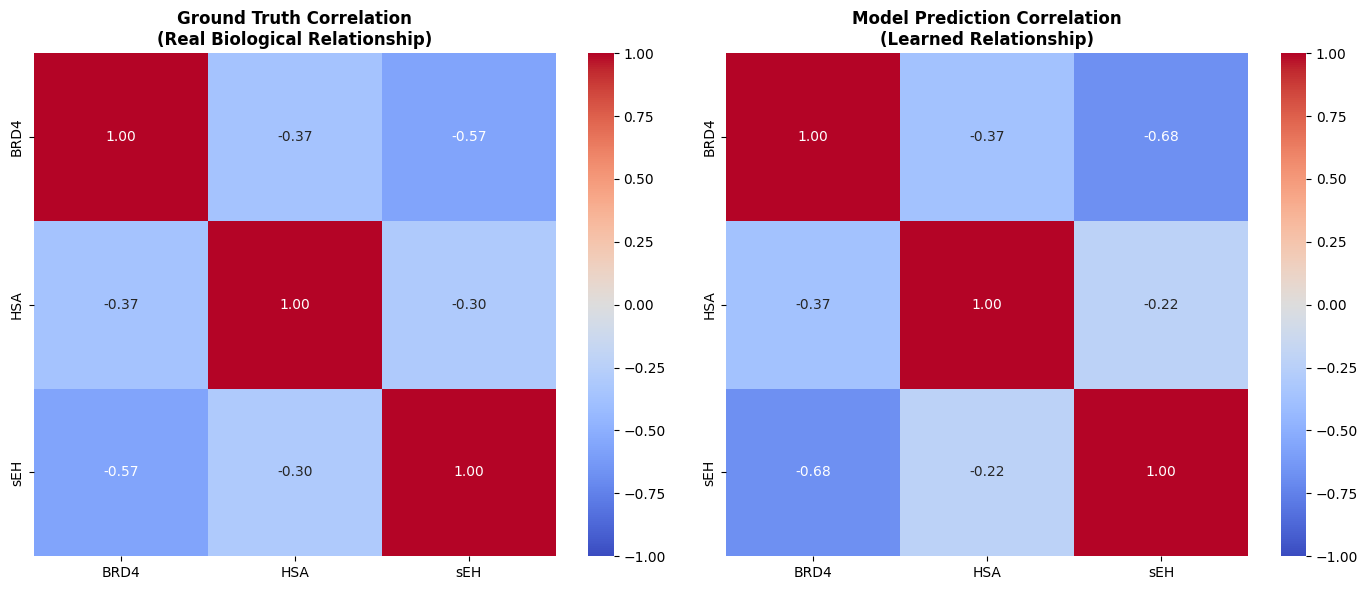

In [47]:
def plot_correlation_comparison(y_true, y_prob, targets):
    """
    Compares the label correlation in Ground Truth vs Predictions.
    """
    # Compute Pearson correlation matrices
    corr_true = pd.DataFrame(y_true, columns=targets).corr()
    corr_pred = pd.DataFrame(y_prob, columns=targets).corr()
    
    fig, axes = plt.subplots(1, 2, figsize=(14, 6))
    
    # Plot Truth
    sns.heatmap(corr_true, annot=True, cmap='coolwarm', vmin=-1, vmax=1, ax=axes[0], fmt='.2f')
    axes[0].set_title('Ground Truth Correlation\n(Real Biological Relationship)', fontsize=12, fontweight='bold')
    
    # Plot Model
    sns.heatmap(corr_pred, annot=True, cmap='coolwarm', vmin=-1, vmax=1, ax=axes[1], fmt='.2f')
    axes[1].set_title('Model Prediction Correlation\n(Learned Relationship)', fontsize=12, fontweight='bold')
    
    plt.tight_layout()
    plt.show()

plot_correlation_comparison(y_te, te_prob, CFG.targets)

Running t-SNE on fused embeddings...


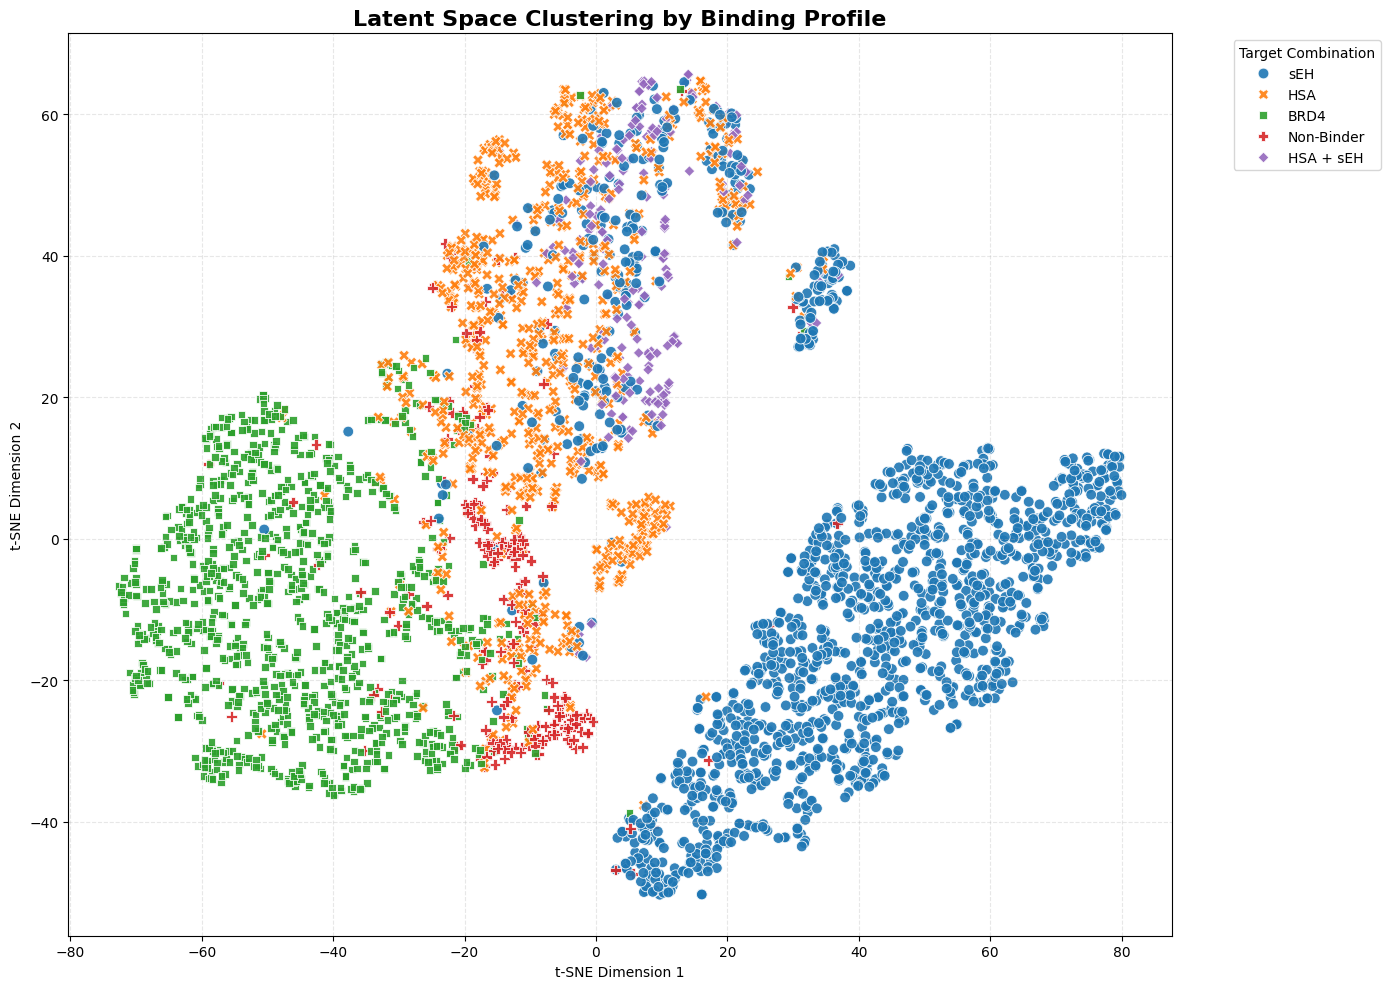

In [48]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.manifold import TSNE

# 1. Define Binding Labels (e.g., [1, 0, 1] -> "BRD4 + sEH")
def get_binding_label(row, target_names):
    active_targets = [target_names[i] for i, val in enumerate(row) if val == 1]
    if len(active_targets) == 0:
        return "Non-Binder"
    elif len(active_targets) == 3:
        return "Promiscuous (All 3)"
    else:
        return " + ".join(active_targets)

# 2. Prepare Data (Downsample for speed/clarity)
N_SAMPLES = 4000
indices = np.random.choice(len(te_fused), size=min(len(te_fused), N_SAMPLES), replace=False)
X_sub = te_fused[indices]
y_sub = y_te[indices]

# Generate labels for these samples
binding_modes = [get_binding_label(row, CFG.targets) for row in y_sub]

# 3. Run t-SNE
print("Running t-SNE on fused embeddings...")
tsne = TSNE(n_components=2, perplexity=30, random_state=42, init='pca', learning_rate='auto')
X_embedded = tsne.fit_transform(X_sub)

# 4. Plot
plt.figure(figsize=(14, 10))
df_tsne = pd.DataFrame({
    'x': X_embedded[:, 0],
    'y': X_embedded[:, 1],
    'Binding Mode': binding_modes
})

# Define a palette that highlights specific groups
unique_modes = sorted(df_tsne['Binding Mode'].unique())
palette = sns.color_palette("tab10", n_colors=len(unique_modes))

sns.scatterplot(
    data=df_tsne, x='x', y='y', hue='Binding Mode', 
    palette=palette, style='Binding Mode', s=60, alpha=0.9
)

plt.title("Latent Space Clustering by Binding Profile", fontsize=16, fontweight='bold')
plt.xlabel("t-SNE Dimension 1")
plt.ylabel("t-SNE Dimension 2")
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', title="Target Combination")
plt.grid(True, linestyle='--', alpha=0.3)
plt.tight_layout()
plt.show()

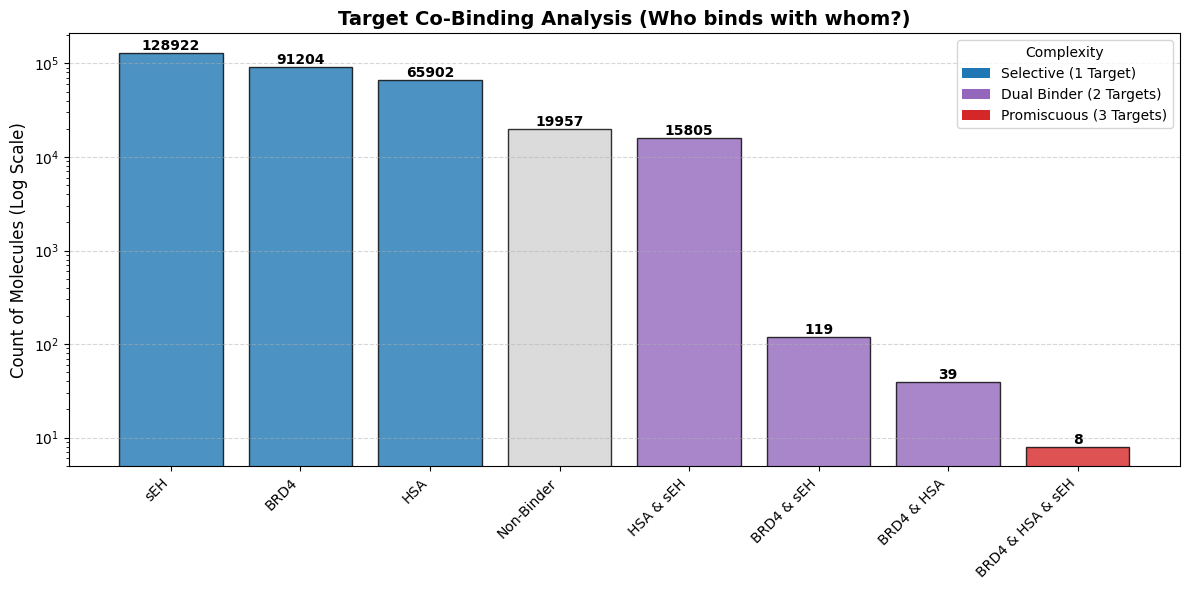

In [49]:
import matplotlib.pyplot as plt
import pandas as pd

# 1. Calculate counts for every combination of targets
df_targets = pd.DataFrame(y_te, columns=CFG.targets)
# Create a string signature for each row, e.g., "1-0-1"
df_targets['signature'] = df_targets.apply(lambda x: "-".join(x.astype(str)), axis=1)

# Count frequencies
counts = df_targets['signature'].value_counts()

# Decode signatures for labeling
labels = []
values = []
colors = []

# Define colors for complexity: Gray (0), Blue (1 target), Purple (2 targets), Red (3 targets)
color_map = {0: 'lightgray', 1: '#1f77b4', 2: '#9467bd', 3: '#d62728'}

for sig in counts.index:
    bits = [int(b) for b in sig.split('-')]
    n_active = sum(bits)
    
    # Generate label name
    active_names = [CFG.targets[i] for i, b in enumerate(bits) if b == 1]
    if n_active == 0:
        label = "Non-Binder"
    else:
        label = " & ".join(active_names)
        
    labels.append(label)
    values.append(counts[sig])
    colors.append(color_map[n_active])

# 2. Plot Bar Chart
plt.figure(figsize=(12, 6))
bars = plt.bar(labels, values, color=colors, edgecolor='black', alpha=0.8)

# Add counts on top
for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2., height,
             f'{int(height)}',
             ha='center', va='bottom', fontsize=10, fontweight='bold')

plt.yscale('log') # Log scale is crucial because Non-Binders usually dominate
plt.ylabel('Count of Molecules (Log Scale)', fontsize=12)
plt.title('Target Co-Binding Analysis (Who binds with whom?)', fontsize=14, fontweight='bold')
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', linestyle='--', alpha=0.5)

# Custom legend
from matplotlib.patches import Patch
legend_elements = [
    Patch(facecolor='#1f77b4', label='Selective (1 Target)'),
    Patch(facecolor='#9467bd', label='Dual Binder (2 Targets)'),
    Patch(facecolor='#d62728', label='Promiscuous (3 Targets)')
]
plt.legend(handles=legend_elements, title="Complexity")
plt.tight_layout()
plt.show()

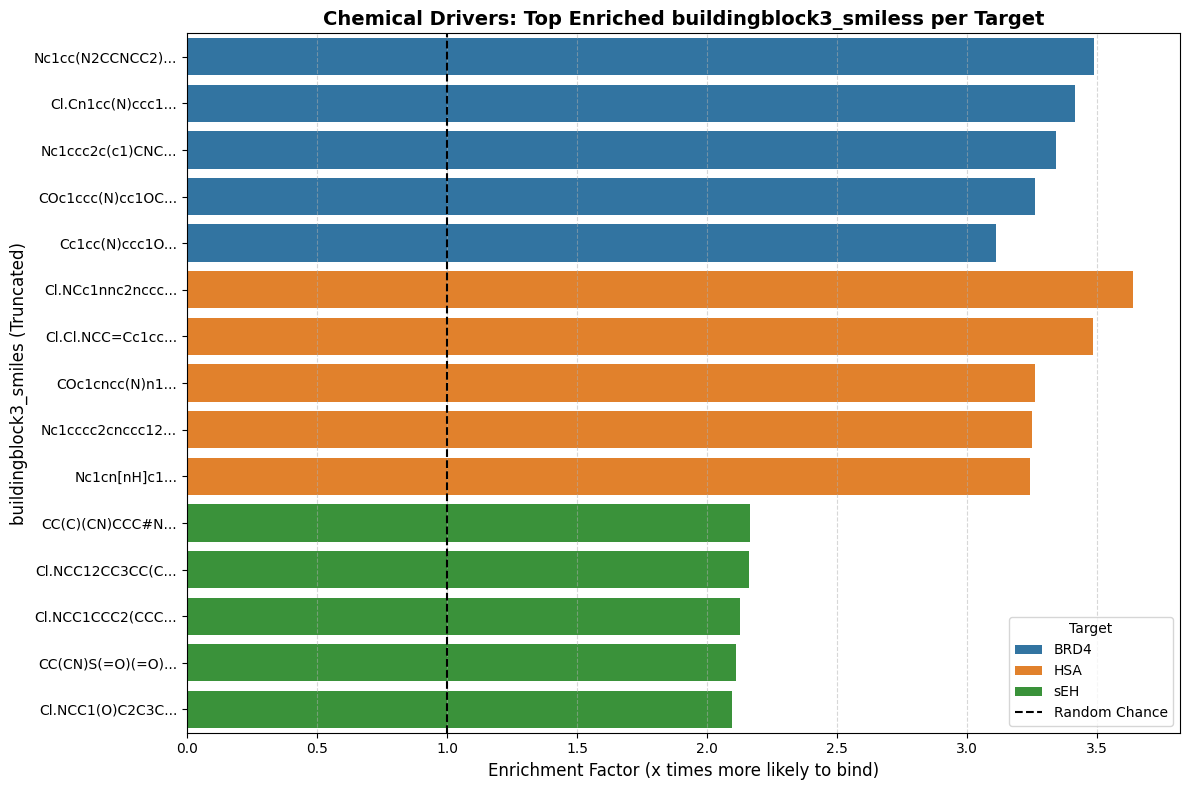

In [50]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

def plot_chemical_drivers(test_df, y_true, bb_col='buildingblock3_smiles', top_n=5):
    """
    Identifies building blocks that strongly increase the probability of binding 
    to a specific target compared to the background rate.
    """
    results = []
    
    # Calculate background binding rate for each target
    bg_rates = y_true.mean(axis=0)
    
    # Analyze each target separately
    for i, target in enumerate(CFG.targets):
        # Create temporary DF
        df_analysis = test_df[[bb_col]].copy()
        df_analysis['is_active'] = y_true[:, i]
        
        # Calculate binding rate per building block
        # We only consider blocks that appear at least 50 times to avoid noise
        stats = df_analysis.groupby(bb_col)['is_active'].agg(['mean', 'count'])
        stats = stats[stats['count'] > 50]
        
        # Calculate "Enrichment" = (Block Rate) / (Background Rate)
        stats['enrichment'] = stats['mean'] / bg_rates[i]
        
        # Get Top N enriched blocks
        top_blocks = stats.sort_values('enrichment', ascending=False).head(top_n)
        
        for bb, row in top_blocks.iterrows():
            results.append({
                'Target': target,
                'Building Block': bb[:15] + "...", # Truncate for plot
                'Enrichment': row['enrichment'],
                'Count': row['count']
            })
            
    df_res = pd.DataFrame(results)
    
    # Plot
    plt.figure(figsize=(12, 8))
    sns.barplot(data=df_res, x='Enrichment', y='Building Block', hue='Target', dodge=False)
    
    plt.axvline(1.0, color='k', linestyle='--', label='Random Chance')
    plt.title(f'Chemical Drivers: Top Enriched {bb_col}s per Target', fontsize=14, fontweight='bold')
    plt.xlabel('Enrichment Factor (x times more likely to bind)', fontsize=12)
    plt.ylabel(f'{bb_col} (Truncated)', fontsize=12)
    plt.legend(title='Target')
    plt.grid(axis='x', linestyle='--', alpha=0.5)
    plt.tight_layout()
    plt.show()
    
    return df_res

# Run the analysis (Ensure test_df is defined from your split)
# We focus on BB3 because it's often the most variable part in DEL libraries
drivers = plot_chemical_drivers(test_df, y_te, bb_col='buildingblock3_smiles')

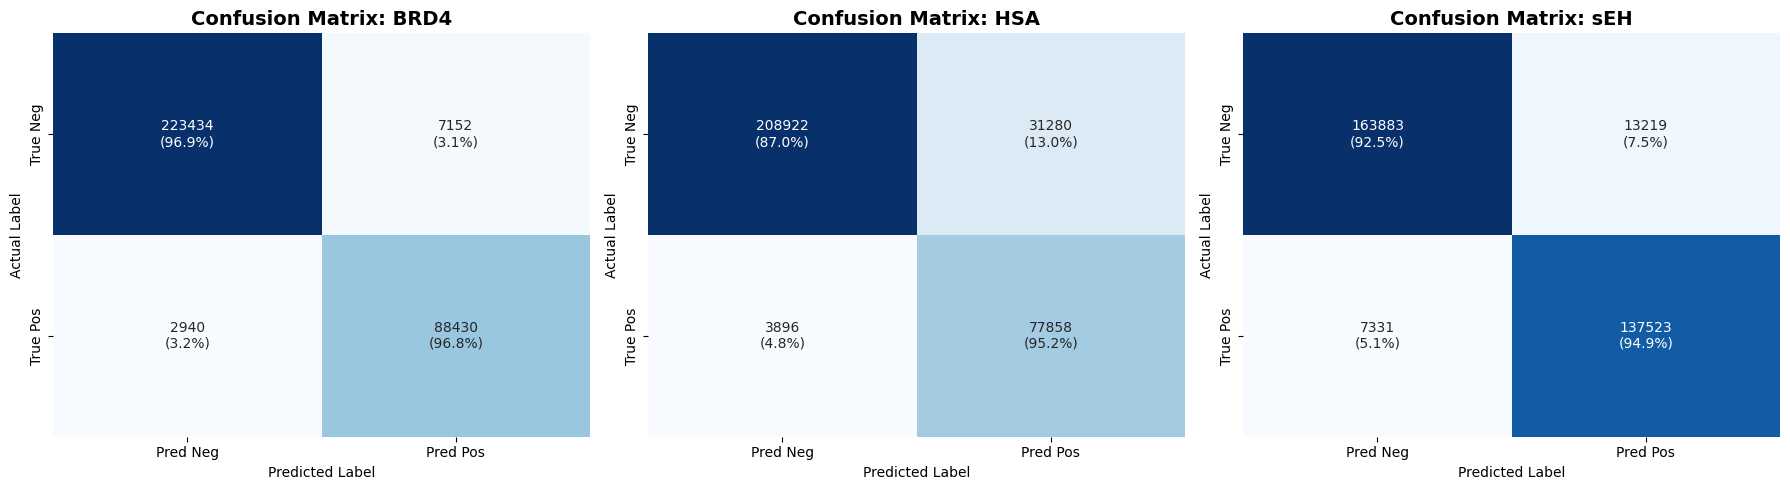

In [51]:
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

def plot_multilabel_confusion_matrix(y_true, y_prob, targets, threshold=0.5):
    """
    Plots a Confusion Matrix for each target side-by-side.
    """
    # Convert probs to binary predictions
    y_pred = (y_prob >= threshold).astype(int)
    
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    
    for i, target in enumerate(targets):
        cm = confusion_matrix(y_true[:, i], y_pred[:, i])
        
        # Calculate percentages for clearer interpretation
        cm_norm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]
        
        # Annotations: Count + (Percentage)
        annot = np.empty_like(cm).astype(str)
        nrows, ncols = cm.shape
        for r in range(nrows):
            for c in range(ncols):
                cnt = cm[r, c]
                pct = cm_norm[r, c] * 100
                annot[r, c] = f"{cnt}\n({pct:.1f}%)"
        
        sns.heatmap(cm, annot=annot, fmt='', cmap='Blues', ax=axes[i], cbar=False,
                    xticklabels=['Pred Neg', 'Pred Pos'],
                    yticklabels=['True Neg', 'True Pos'])
        
        axes[i].set_title(f'Confusion Matrix: {target}', fontweight='bold', fontsize=14)
        axes[i].set_ylabel('Actual Label')
        axes[i].set_xlabel('Predicted Label')
    
    plt.tight_layout()
    plt.show()

# Run the plot
plot_multilabel_confusion_matrix(y_te, te_prob, CFG.targets, threshold=0.5)

In [54]:
import pandas as pd
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, average_precision_score, matthews_corrcoef

def generate_metrics_table(y_true, y_prob, targets, threshold=0.5):
    y_pred = (y_prob >= threshold).astype(int)
    
    metrics_list = []
    
    for i, target in enumerate(targets):
        # Calculate all key metrics
        acc = accuracy_score(y_true[:, i], y_pred[:, i])
        prec = precision_score(y_true[:, i], y_pred[:, i], zero_division=0)
        rec = recall_score(y_true[:, i], y_pred[:, i], zero_division=0)
        f1 = f1_score(y_true[:, i], y_pred[:, i], zero_division=0)
        auc = roc_auc_score(y_true[:, i], y_prob[:, i])
        ap = average_precision_score(y_true[:, i], y_prob[:, i])
        mcc = matthews_corrcoef(y_true[:, i], y_pred[:, i])
        
        metrics_list.append({
            "Target": target,
            "Accuracy": acc,
            "Precision": prec,
            "Recall": rec,
            "F1-Score": f1,
            "AUC-ROC": auc,
            "mAP (PR-AUC)": ap,
            "MCC": mcc
        })
        
    # Calculate Macro Average
    df = pd.DataFrame(metrics_list)
    numeric_cols = df.columns.drop("Target")
    
    # Create the average row
    avg_row = df[numeric_cols].mean()
    df.loc['Average'] = avg_row
    df.loc['Average', 'Target'] = 'MACRO AVG'
    
    # Styling for display
    # FIX: Explicitly apply format ONLY to numeric_cols
    return df.style.background_gradient(subset=numeric_cols).format("{:.4f}", subset=numeric_cols)

# Display the table
metrics_table = generate_metrics_table(y_te, te_prob, CFG.targets)
display(metrics_table)

,Target,Accuracy,Precision,Recall,F1-Score,AUC-ROC,mAP (PR-AUC),MCC
0,BRD4,0.9687,0.9252,0.9678,0.9460,0.9957,0.9891,0.9244
1,HSA,0.8907,0.7134,0.9523,0.8157,0.9621,0.8813,0.7559
2,sEH,0.9362,0.9123,0.9494,0.9305,0.9887,0.9867,0.8721
Average,MACRO AVG,0.9319,0.8503,0.9565,0.8974,0.9822,0.9524,0.8508


Computing chemical properties for test set...


Processing Molecules: 100%|██████████| 321956/321956 [04:11<00:00, 1281.44it/s]


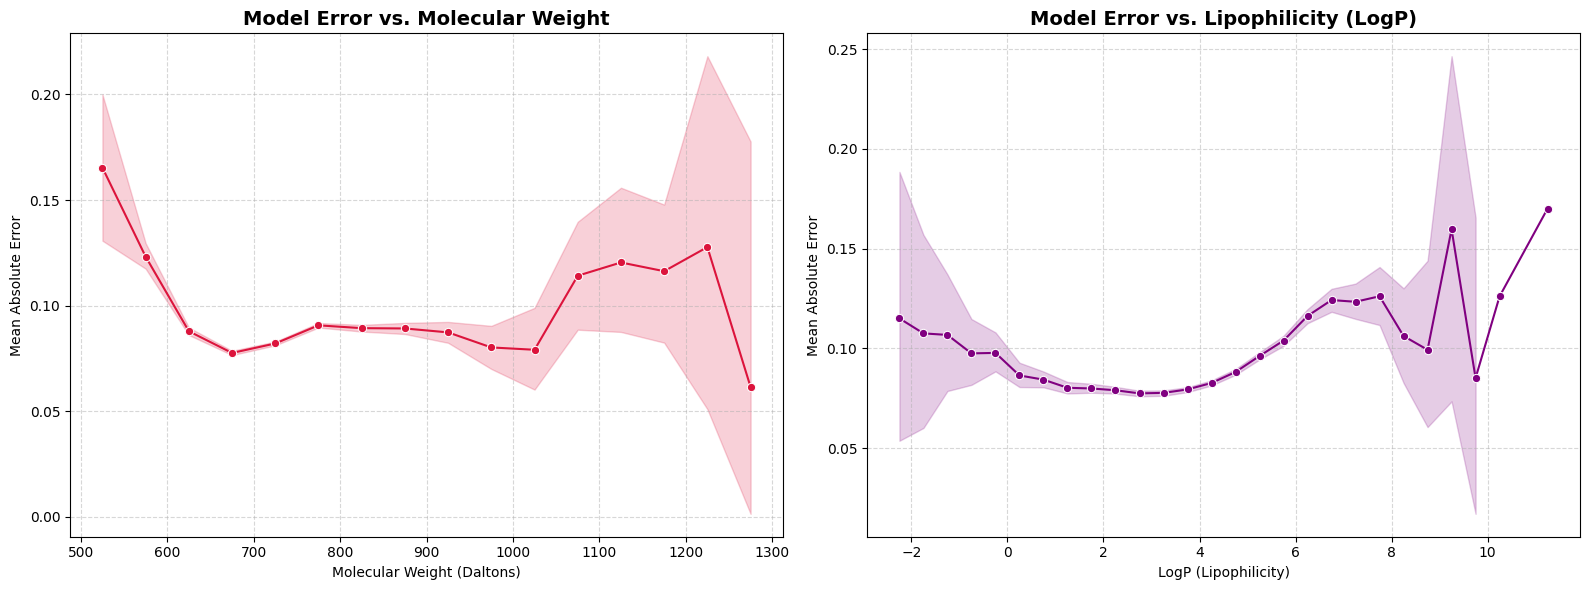

Interpretation: A rising line indicates the model struggles with larger or more hydrophobic molecules.


In [57]:
from rdkit import Chem
from rdkit.Chem import Descriptors
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from tqdm.auto import tqdm

def plot_performance_by_property(test_df, y_true, y_prob, targets):
    """
    Plots Model Error Rate vs Molecular Weight and LogP.
    Fixed: Converts pandas Interval objects to numeric midpoints for plotting.
    """
    print("Computing chemical properties for test set...")
    
    # 1. Calculate Properties (MW and LogP)
    mw_list = []
    logp_list = []
    
    # Use tqdm for progress bar
    for s in tqdm(test_df['molecule_smiles'], desc="Processing Molecules"):
        try:
            m = Chem.MolFromSmiles(s)
            if m:
                mw_list.append(Descriptors.MolWt(m))
                logp_list.append(Descriptors.MolLogP(m))
            else:
                mw_list.append(np.nan)
                logp_list.append(np.nan)
        except:
            mw_list.append(np.nan)
            logp_list.append(np.nan)
    
    # 2. Prepare Dataframe
    df_perf = pd.DataFrame({
        'MW': mw_list,
        'LogP': logp_list
    })
    
    # Calculate Mean Absolute Error (MAE) per sample
    # (Sum of absolute differences between truth and prob)
    df_perf['Error'] = np.abs(y_true - y_prob).mean(axis=1)
    
    # Drop rows where RDKit failed
    df_perf = df_perf.dropna()

    # 3. Plotting
    fig, axes = plt.subplots(1, 2, figsize=(16, 6))
    
    # --- Molecular Weight ---
    # Binning MW into chunks of 50 Daltons
    max_mw = df_perf['MW'].max()
    # Create bins
    mw_bins = pd.cut(df_perf['MW'], bins=range(200, int(max_mw)+100, 50))
    # FIX: Convert Interval to Midpoint (Numeric) for plotting
    df_perf['MW_Bin_Mid'] = mw_bins.apply(lambda x: x.mid)
    
    sns.lineplot(data=df_perf, x='MW_Bin_Mid', y='Error', marker='o', color='crimson', ax=axes[0])
    axes[0].set_title('Model Error vs. Molecular Weight', fontsize=14, fontweight='bold')
    axes[0].set_xlabel('Molecular Weight (Daltons)')
    axes[0].set_ylabel('Mean Absolute Error')
    axes[0].grid(True, linestyle='--', alpha=0.5)
    
    # --- LogP (Hydrophobicity) ---
    # Binning LogP into chunks of 0.5
    min_logp = int(np.floor(df_perf['LogP'].min()))
    max_logp = int(np.ceil(df_perf['LogP'].max()))
    
    logp_bins = pd.cut(df_perf['LogP'], bins=np.arange(min_logp, max_logp+1, 0.5))
    # FIX: Convert Interval to Midpoint (Numeric)
    df_perf['LogP_Bin_Mid'] = logp_bins.apply(lambda x: x.mid)
    
    sns.lineplot(data=df_perf, x='LogP_Bin_Mid', y='Error', marker='o', color='purple', ax=axes[1])
    axes[1].set_title('Model Error vs. Lipophilicity (LogP)', fontsize=14, fontweight='bold')
    axes[1].set_xlabel('LogP (Lipophilicity)')
    axes[1].set_ylabel('Mean Absolute Error')
    axes[1].grid(True, linestyle='--', alpha=0.5)
    
    plt.tight_layout()
    plt.show()
    
    print("Interpretation: A rising line indicates the model struggles with larger or more hydrophobic molecules.")

# Run the analysis
plot_performance_by_property(test_df, y_te, te_prob, CFG.targets)

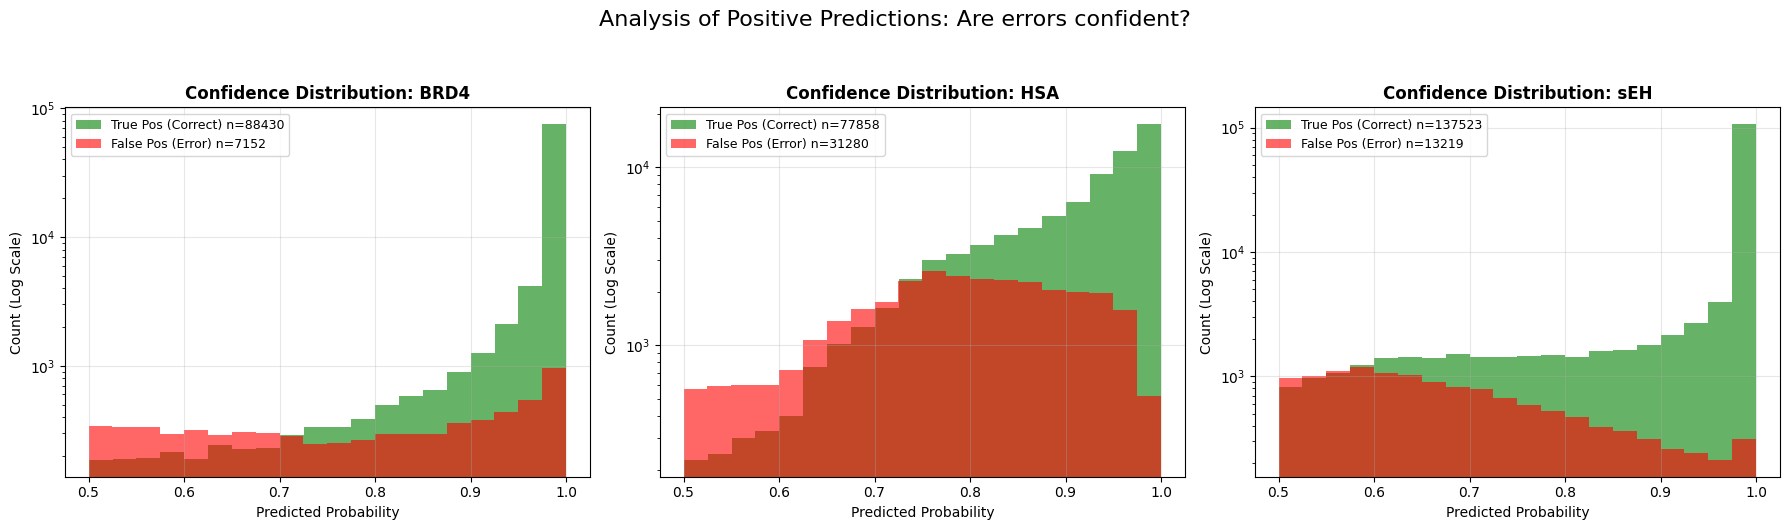

In [58]:
def plot_error_confidence(y_true, y_prob, targets):
    """
    Histograms of predicted probabilities for True Positives vs False Positives.
    Checks if the model is 'Confidently Wrong'.
    """
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    
    for i, target in enumerate(targets):
        # Extract probabilities
        probs = y_prob[:, i]
        true_labels = y_true[:, i]
        
        # Identify TP (True Positives) and FP (False Positives)
        # We consider predictions > 0.5 as positive
        mask_pred_pos = probs > 0.5
        
        tp_probs = probs[mask_pred_pos & (true_labels == 1)]
        fp_probs = probs[mask_pred_pos & (true_labels == 0)]
        
        # Plot
        axes[i].hist(tp_probs, bins=20, alpha=0.6, color='green', label=f'True Pos (Correct) n={len(tp_probs)}')
        axes[i].hist(fp_probs, bins=20, alpha=0.6, color='red', label=f'False Pos (Error) n={len(fp_probs)}')
        
        axes[i].set_title(f'Confidence Distribution: {target}', fontweight='bold')
        axes[i].set_xlabel('Predicted Probability')
        axes[i].set_ylabel('Count (Log Scale)')
        axes[i].set_yscale('log') # Log scale to see the small number of errors
        axes[i].legend(loc='upper left', fontsize=9)
        axes[i].grid(True, alpha=0.3)
        
    plt.suptitle("Analysis of Positive Predictions: Are errors confident?", fontsize=16, y=1.05)
    plt.tight_layout()
    plt.show()

plot_error_confidence(y_te, te_prob, CFG.targets)

Using device: cuda
Selected Random Sample Index: 72426
Active Targets: BRD4
Visualizing SMILES: CC(OC(C)(C)C)C(Nc1nc(NCc2cscc2C(F)(F)F)nc(NCc2cn(-c3ccccc3)nc2-c2ccncc2)n1)C(=O)N[Dy]
An error occurred: 'QuadContourSet' object has no attribute 'collections'


<Figure size 800x600 with 0 Axes>

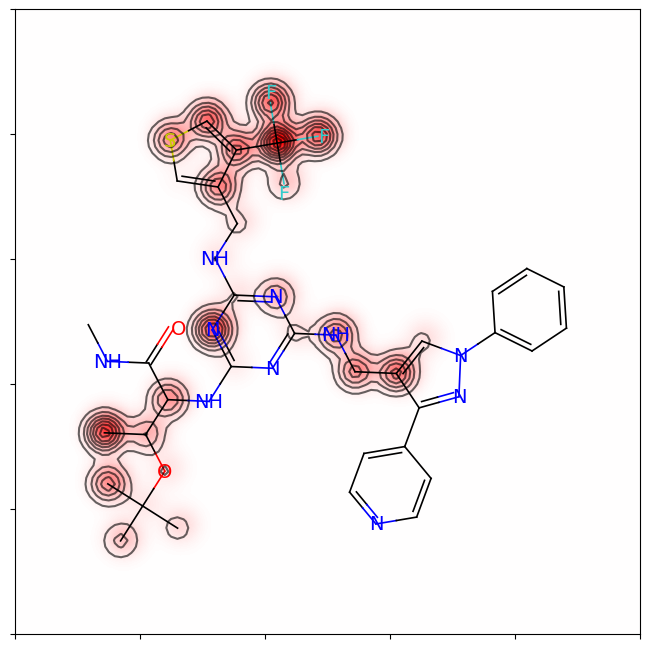

In [99]:
import torch
import numpy as np
import matplotlib.pyplot as plt
from rdkit import Chem
from rdkit.Chem import Draw
from rdkit.Chem.Draw import SimilarityMaps
import matplotlib.cm as cm
from transformers import AutoTokenizer

# --- 1. Setup Device Automatically ---
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

def visualize_model_attention(model, tokenizer, smiles, target_names, device):
    """
    Visualizes which parts of the molecule the Transformer focused on.
    """
    model.eval()
    model.to(device)
    
    # 2. Tokenize SMILES
    clean_smiles = smiles.replace('[Dy]', 'C') # Clean dummy tags
    
    inputs = tokenizer(smiles, return_tensors="pt", padding=True, truncation=True, max_length=128)
    input_ids = inputs['input_ids'].to(device)
    attention_mask = inputs['attention_mask'].to(device)
    
    # 3. Forward Pass with Attention Extraction
    with torch.no_grad():
        # Check for various model attribute names
        if hasattr(model, 'encoder'):
            base_model = model.encoder
        elif hasattr(model, 'transformer'):
            base_model = model.transformer
        elif hasattr(model, 'roberta'):
            base_model = model.roberta
        else:
            print("Error: Could not find the underlying Transformer in your model.")
            return

        outputs = base_model(
            input_ids=input_ids, 
            attention_mask=attention_mask, 
            output_attentions=True
        )
        
        # Get Last Layer Attention: (Batch, Heads, Seq_Len, Seq_Len)
        attentions = outputs.attentions[-1] 
        attn_avg = attentions[0].mean(dim=0).cpu().numpy()

    # 4. Map Tokens to Atoms
    cls_attention = attn_avg[0, :] 
    token_weights = cls_attention[1:-1] 
    tokens = tokenizer.convert_ids_to_tokens(input_ids[0][1:-1])
    
    # 5. Create RDKit Mol
    mol = Chem.MolFromSmiles(clean_smiles)
    if not mol:
        print(f"Error parsing SMILES: {smiles}")
        return

    # Normalize weights
    if len(token_weights) > 0:
        w_min, w_max = token_weights.min(), token_weights.max()
        if w_max > w_min:
            token_weights = (token_weights - w_min) / (w_max - w_min)
    
    # Map weights to atoms (Heuristic)
    atom_weights = np.zeros(mol.GetNumAtoms())
    atom_idx = 0
    
    for i, token in enumerate(tokens):
        token_str = token.replace('Ġ', '')
        # Assign weight if it looks like an atom
        if token_str.isalpha() or ('[' in token_str):
            if atom_idx < len(atom_weights):
                atom_weights[atom_idx] = token_weights[i] if i < len(token_weights) else 0
                atom_idx += 1
    
    # 6. Plotting
    fig = plt.figure(figsize=(8, 6))
    
    Draw.SimilarityMaps.GetSimilarityMapFromWeights(
        mol, 
        atom_weights.tolist(), 
        colorMap=cm.bwr, 
        contourLines=10,
        alpha=0.6
    )
    
    plt.title(f"Attention Map: Which atoms drove the prediction?", fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()

# --- RUN THE VISUALIZATION ---

# 1. Find all "Active" molecules (binders) in the test set
active_indices = np.where(y_te.sum(axis=1) > 0)[0]

if len(active_indices) > 0:
    # 2. Pick a RANDOM active molecule every time
    idx = np.random.choice(active_indices)
    
    # Get its targets
    labels = y_te[idx]
    active_targets = [CFG.targets[i] for i, val in enumerate(labels) if val == 1]
    
    print(f"Selected Random Sample Index: {idx}")
    print(f"Active Targets: {', '.join(active_targets)}")
else:
    # Fallback if no actives exist (rare)
    idx = np.random.randint(0, len(test_df))
    print("No active molecules found. Picking random inactive.")

sample_smiles = test_df.iloc[idx]['molecule_smiles']
print(f"Visualizing SMILES: {sample_smiles}")

try:
    tokenizer = AutoTokenizer.from_pretrained('seyonec/ChemBERTa-zinc-base-v1')
    visualize_model_attention(model, tokenizer, sample_smiles, CFG.targets, device=device)
except Exception as e:
    print(f"An error occurred: {e}")

Generating Chemical Space Map for Target: BRD4...


Calc Properties: 100%|██████████| 321956/321956 [04:06<00:00, 1307.08it/s]


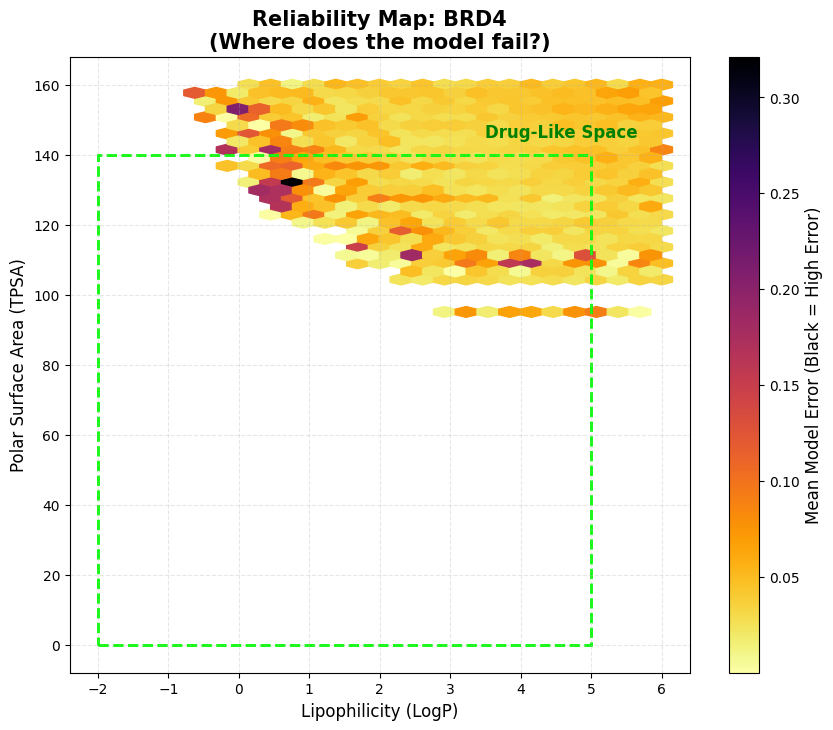

Interpretation: Lighter regions indicate the model is highly reliable.
If the 'Drug-Like' box is mostly light, your model is clinically relevant.


In [71]:
import matplotlib.pyplot as plt
import seaborn as sns
from rdkit import Chem
from rdkit.Chem import Descriptors
import pandas as pd
import numpy as np
from tqdm.auto import tqdm

def plot_chemical_space_error(test_df, y_true, y_prob, target_index=0):
    """
    Visualizes Model Error mapped onto the classic 'Drug-Like' Chemical Space
    (TPSA vs LogP).
    """
    target_name = CFG.targets[target_index]
    print(f"Generating Chemical Space Map for Target: {target_name}...")
    
    tpsa_list = []
    logp_list = []
    
    # 1. Compute Properties
    for s in tqdm(test_df['molecule_smiles'], desc="Calc Properties"):
        m = Chem.MolFromSmiles(s)
        if m:
            tpsa_list.append(Descriptors.TPSA(m))
            logp_list.append(Descriptors.MolLogP(m))
        else:
            tpsa_list.append(np.nan)
            logp_list.append(np.nan)
            
    # 2. Prepare Data
    df_chem = pd.DataFrame({
        'TPSA': tpsa_list,
        'LogP': logp_list,
        'True': y_true[:, target_index],
        'Prob': y_prob[:, target_index]
    })
    
    # Calculate Absolute Error
    df_chem['Error'] = np.abs(df_chem['True'] - df_chem['Prob'])
    df_chem = df_chem.dropna()
    
    # Filter for visual clarity (remove extreme outliers)
    df_chem = df_chem[(df_chem['TPSA'] < 160) & (df_chem['LogP'].between(-2, 6))]
    
    # 3. Plotting (Hexbin for density)
    fig, ax = plt.subplots(figsize=(10, 8))
    
    # We use hexbin to show the AVERAGE ERROR in that region of chemical space
    hb = ax.hexbin(df_chem['LogP'], df_chem['TPSA'], C=df_chem['Error'], 
                   gridsize=25, cmap='inferno_r', reduce_C_function=np.mean,
                   mincnt=5, edgecolors='face')
    
    cb = fig.colorbar(hb, ax=ax)
    cb.set_label('Mean Model Error (Black = High Error)', fontsize=12)
    
    ax.set_title(f'Reliability Map: {target_name}\n(Where does the model fail?)', fontsize=15, fontweight='bold')
    ax.set_xlabel('Lipophilicity (LogP)', fontsize=12)
    ax.set_ylabel('Polar Surface Area (TPSA)', fontsize=12)
    ax.grid(True, linestyle='--', alpha=0.3)
    
    # Add "Drug-Like" Box (Lipinski Rule of 5 approx)
    # LogP < 5, TPSA < 140
    import matplotlib.patches as patches
    rect = patches.Rectangle((-2, 0), 7, 140, linewidth=2, edgecolor='lime', facecolor='none', linestyle='--')
    ax.add_patch(rect)
    ax.text(3.5, 145, 'Drug-Like Space', color='green', fontweight='bold', fontsize=12)
    
    plt.show()
    print("Interpretation: Lighter regions indicate the model is highly reliable.")
    print("If the 'Drug-Like' box is mostly light, your model is clinically relevant.")

# Run for the first target (BRD4)
plot_chemical_space_error(test_df, y_te, te_prob, target_index=0)

Latent Space Analysis for Target: HSA


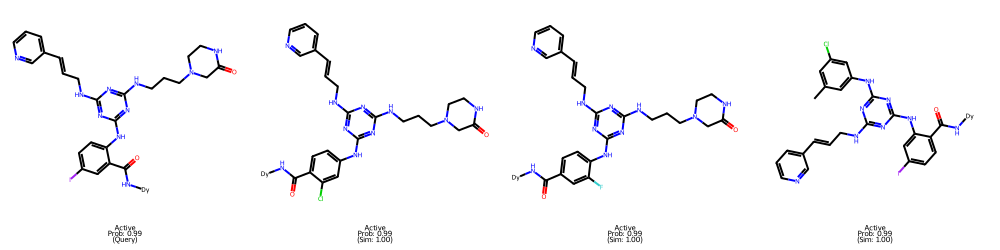

Interpretation: If the Neighbors are also 'Active', the model has learned a robust structural cluster.


In [100]:
from sklearn.neighbors import NearestNeighbors
from rdkit.Chem import Draw

def visualize_latent_neighbors(test_df, embeddings, y_true, y_prob, target_index=0, n_neighbors=4):
    """
    Picks an active molecule and finds its nearest neighbors in the learned embedding space.
    Checks if 'Chemical Similarity' matches 'Model Similarity'.
    """
    target_name = CFG.targets[target_index]
    
    # 1. Fit Nearest Neighbor on Test Embeddings
    # (In a real scenario, you'd fit on Train and query Test, but checking Test internal consistency is also valid)
    nn = NearestNeighbors(n_neighbors=n_neighbors, metric='cosine')
    nn.fit(embeddings)
    
    # 2. Pick a high-confidence True Positive
    # (True Label = 1, Prob > 0.9)
    candidates = np.where((y_true[:, target_index] == 1) & (y_prob[:, target_index] > 0.9))[0]
    
    if len(candidates) == 0:
        print("No high confidence positives found.")
        return
        
    query_idx = np.random.choice(candidates)
    
    # 3. Find Neighbors
    distances, indices = nn.kneighbors(embeddings[query_idx].reshape(1, -1))
    neighbor_indices = indices[0] # The first one is the query itself
    
    # 4. Prepare visualization
    mols = []
    legends = []
    
    for idx in neighbor_indices:
        smiles = test_df.iloc[idx]['molecule_smiles']
        true_label = y_true[idx, target_index]
        prob = y_prob[idx, target_index]
        dist = 1.0 - np.dot(embeddings[query_idx], embeddings[idx]) / (np.linalg.norm(embeddings[query_idx]) * np.linalg.norm(embeddings[idx]))
        
        mol = Chem.MolFromSmiles(smiles)
        mols.append(mol)
        
        status = "Active" if true_label == 1 else "Inactive"
        is_query = "(Query)" if idx == query_idx else f"(Sim: {1-dist:.2f})"
        
        legends.append(f"{status}\nProb: {prob:.2f}\n{is_query}")
        
    # 5. Draw
    img = Draw.MolsToGridImage(mols, molsPerRow=n_neighbors, subImgSize=(250, 250), 
                               legends=legends, useSVG=False)
    
    print(f"Latent Space Analysis for Target: {target_name}")
    display(img)
    print("Interpretation: If the Neighbors are also 'Active', the model has learned a robust structural cluster.")

# Run the visualizer
visualize_latent_neighbors(test_df, te_fused, y_te, te_prob, target_index=1)

Analyzing Scaffold Robustness for: BRD4...


Extracting Scaffolds: 100%|██████████| 321956/321956 [02:37<00:00, 2045.34it/s]


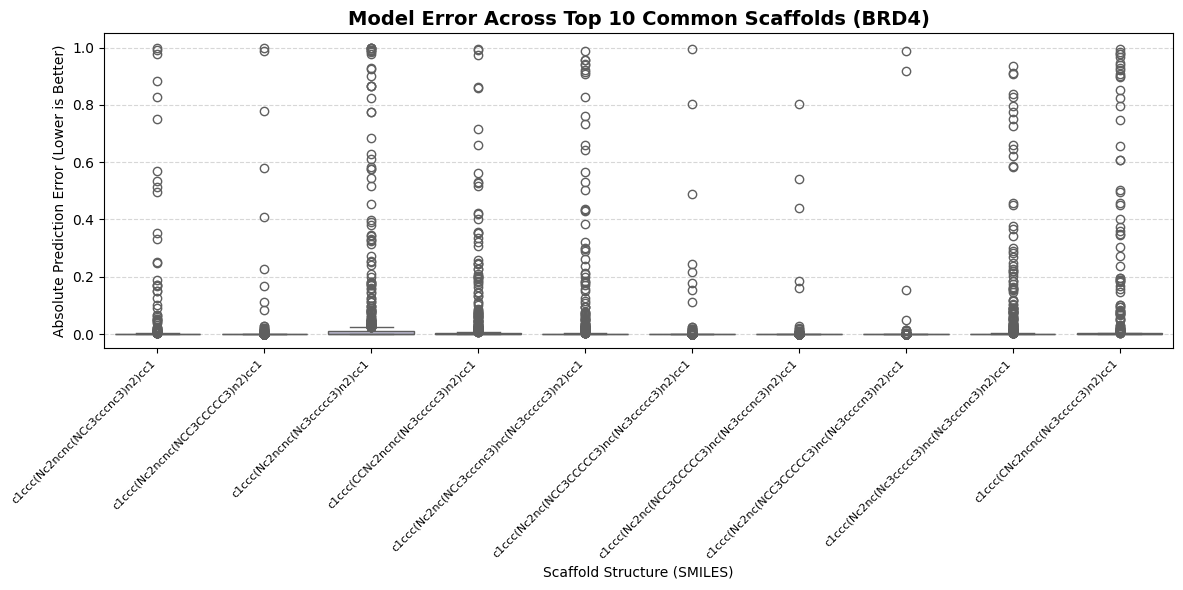

Interpretation: If the boxes are all low and level, the model is robust across different chemical backbones.
If one box is much higher, the model struggles with that specific scaffold family.


In [79]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from rdkit import Chem
from rdkit.Chem.Scaffolds import MurckoScaffold
from tqdm.auto import tqdm

def plot_scaffold_robustness(test_df, y_true, y_prob, target_index=0, top_n=10):
    """
    Extracts Murcko Scaffolds and analyzes model performance per scaffold.
    """
    target_name = CFG.targets[target_index]
    print(f"Analyzing Scaffold Robustness for: {target_name}...")
    
    scaffolds = []
    errors = []
    
    # Calculate absolute error for the specific target
    abs_errors = np.abs(y_true[:, target_index] - y_prob[:, target_index])
    
    for i, s in tqdm(enumerate(test_df['molecule_smiles']), total=len(test_df), desc="Extracting Scaffolds"):
        try:
            mol = Chem.MolFromSmiles(s)
            if mol:
                # Extract the core scaffold (Murcko)
                core = MurckoScaffold.GetScaffoldForMol(mol)
                scaff_smiles = Chem.MolToSmiles(core)
                scaffolds.append(scaff_smiles)
                errors.append(abs_errors[i])
            else:
                scaffolds.append("Invalid")
                errors.append(np.nan)
        except:
            scaffolds.append("Error")
            errors.append(np.nan)
            
    # Create Analysis DataFrame
    df_scaff = pd.DataFrame({
        'Scaffold': scaffolds,
        'Error': errors
    })
    df_scaff = df_scaff.dropna()
    
    # Filter: Only take scaffolds that appear at least 20 times (to be statistically significant)
    counts = df_scaff['Scaffold'].value_counts()
    valid_scaffolds = counts[counts > 20].index
    df_filtered = df_scaff[df_scaff['Scaffold'].isin(valid_scaffolds)]
    
    # Get Top N most frequent scaffolds
    top_scaffolds = df_filtered['Scaffold'].value_counts().head(top_n).index
    df_plot = df_filtered[df_filtered['Scaffold'].isin(top_scaffolds)]
    
    # Shorten scaffold names for plotting
    df_plot['Scaffold_ID'] = df_plot['Scaffold'].astype('category').cat.codes
    
    # PLOTTING
    plt.figure(figsize=(12, 6))
    
    # Boxplot of Error Rates per Scaffold
    sns.boxplot(data=df_plot, x='Scaffold', y='Error', palette="Set3")
    
    plt.title(f'Model Error Across Top {top_n} Common Scaffolds ({target_name})', fontsize=14, fontweight='bold')
    plt.ylabel('Absolute Prediction Error (Lower is Better)')
    plt.xlabel('Scaffold Structure (SMILES)')
    plt.xticks(rotation=45, ha='right', fontsize=8)
    plt.grid(axis='y', linestyle='--', alpha=0.5)
    
    plt.tight_layout()
    plt.show()
    
    print("Interpretation: If the boxes are all low and level, the model is robust across different chemical backbones.")
    print("If one box is much higher, the model struggles with that specific scaffold family.")

# Run for the first target (BRD4)
plot_scaffold_robustness(test_df, y_te, te_prob, target_index=0)

Scanning for functional groups in BRD4 data...


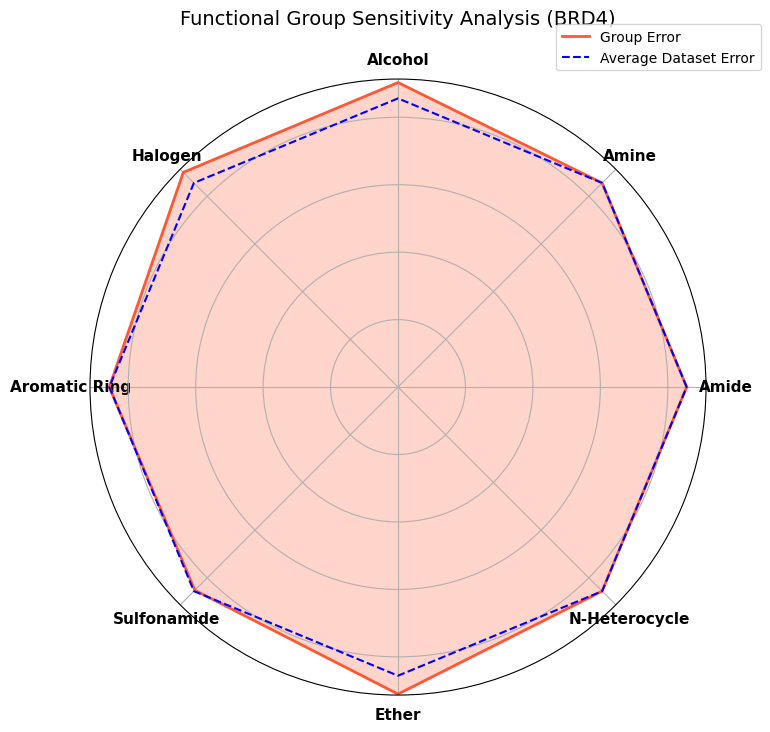

Interpretation: If the Red shape extends far beyond the Blue dashed line for a specific label,
it means the model struggles with that specific chemical group.


In [80]:
import numpy as np
import matplotlib.pyplot as plt
from rdkit import Chem

def plot_functional_group_radar(test_df, y_true, y_prob, target_index=0):
    """
    Checks if specific functional groups cause higher error rates.
    Visualized as a Radar/Spider Chart.
    """
    target_name = CFG.targets[target_index]
    
    # Define SMARTS patterns for common groups
    # You can expand this list based on your dataset
    groups = {
        'Amide': '[NX3][CX3](=[OX1])[#6]',
        'Amine': '[NX3;H2,H1;!$(NC=O)]',
        'Alcohol': '[OX2H]',
        'Halogen': '[F,Cl,Br,I]',
        'Aromatic Ring': 'a',
        'Sulfonamide': '[SX4](=[OX1])(=[OX1])([NX3])',
        'Ether': '[OD2]([#6])[#6]',
        'N-Heterocycle': '[n]'
    }
    
    group_errors = {}
    global_error = np.mean(np.abs(y_true[:, target_index] - y_prob[:, target_index]))
    
    print(f"Scanning for functional groups in {target_name} data...")
    
    # Pre-compile patterns
    patterns = {name: Chem.MolFromSmarts(smart) for name, smart in groups.items()}
    
    # Calculate error for molecules containing each group
    for name, pat in patterns.items():
        indices = []
        for i, s in enumerate(test_df['molecule_smiles']):
            # Quick check: does the string likely contain the atoms? (optimization)
            mol = Chem.MolFromSmiles(s)
            if mol and mol.HasSubstructMatch(pat):
                indices.append(i)
        
        if indices:
            # Get error for these specific molecules
            subset_true = y_true[indices, target_index]
            subset_prob = y_prob[indices, target_index]
            mean_error = np.mean(np.abs(subset_true - subset_prob))
            group_errors[name] = mean_error
        else:
            group_errors[name] = 0.0

    # --- PLOTTING RADAR CHART ---
    labels = list(group_errors.keys())
    values = list(group_errors.values())
    
    # Close the loop for radar chart
    values += values[:1]
    angles = np.linspace(0, 2 * np.pi, len(labels), endpoint=False).tolist()
    angles += angles[:1]
    
    fig, ax = plt.subplots(figsize=(8, 8), subplot_kw=dict(polar=True))
    
    # Plot Data
    ax.plot(angles, values, color='#FF5733', linewidth=2, label='Group Error')
    ax.fill(angles, values, color='#FF5733', alpha=0.25)
    
    # Plot Baseline (Global Average Error)
    baseline_vals = [global_error] * len(values)
    ax.plot(angles, baseline_vals, color='blue', linestyle='--', label='Average Dataset Error')
    
    # Formatting
    ax.set_yticklabels([])
    ax.set_xticks(angles[:-1])
    ax.set_xticklabels(labels, fontsize=11, fontweight='bold')
    ax.set_title(f'Functional Group Sensitivity Analysis ({target_name})', fontsize=14, pad=20)
    ax.legend(loc='upper right', bbox_to_anchor=(1.1, 1.1))
    
    plt.show()
    print("Interpretation: If the Red shape extends far beyond the Blue dashed line for a specific label,")
    print("it means the model struggles with that specific chemical group.")

# Run the radar
plot_functional_group_radar(test_df, y_te, te_prob, target_index=0)

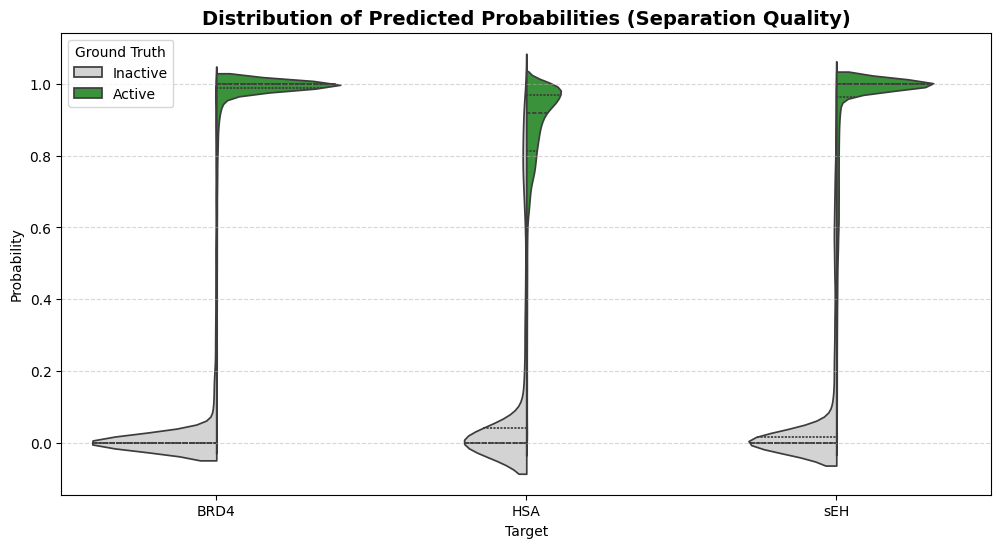

Interpretation: You want 'Inactive' (Gray) to bulge at the bottom (0.0)
and 'Active' (Green) to bulge at the top (1.0). Overlap in the middle represents uncertainty.


In [81]:
import seaborn as sns

def plot_separation_violin(y_true, y_prob, targets):
    """
    Violin plot showing the distribution of predicted probabilities 
    for Active vs Inactive classes.
    """
    # Prepare data for Seaborn
    plot_data = []
    
    for i, target in enumerate(targets):
        # Inactives (0)
        inactives = y_prob[y_true[:, i] == 0, i]
        # Actives (1)
        actives = y_prob[y_true[:, i] == 1, i]
        
        # Downsample Inactives if too large (for speed/visual balance)
        if len(inactives) > 10000:
            inactives = np.random.choice(inactives, 10000, replace=False)
            
        for p in inactives:
            plot_data.append({'Target': target, 'Class': 'Inactive', 'Probability': p})
        for p in actives:
            plot_data.append({'Target': target, 'Class': 'Active', 'Probability': p})
            
    df_violin = pd.DataFrame(plot_data)
    
    plt.figure(figsize=(12, 6))
    sns.violinplot(data=df_violin, x='Target', y='Probability', hue='Class', 
                   split=True, inner='quartile', palette={'Inactive': 'lightgray', 'Active': '#2ca02c'})
    
    plt.title('Distribution of Predicted Probabilities (Separation Quality)', fontsize=14, fontweight='bold')
    plt.grid(axis='y', linestyle='--', alpha=0.5)
    plt.legend(title='Ground Truth')
    plt.show()
    
    print("Interpretation: You want 'Inactive' (Gray) to bulge at the bottom (0.0)")
    print("and 'Active' (Green) to bulge at the top (1.0). Overlap in the middle represents uncertainty.")

plot_separation_violin(y_te, te_prob, CFG.targets)

Running Generalization Test for HSA...


Encoding Train Bank: 100%|██████████| 2000/2000 [00:00<00:00, 3062.80it/s]


Calculating similarity to training set (this takes a moment)...


Checking Test Mols: 100%|██████████| 1000/1000 [00:00<00:00, 1059.18it/s]


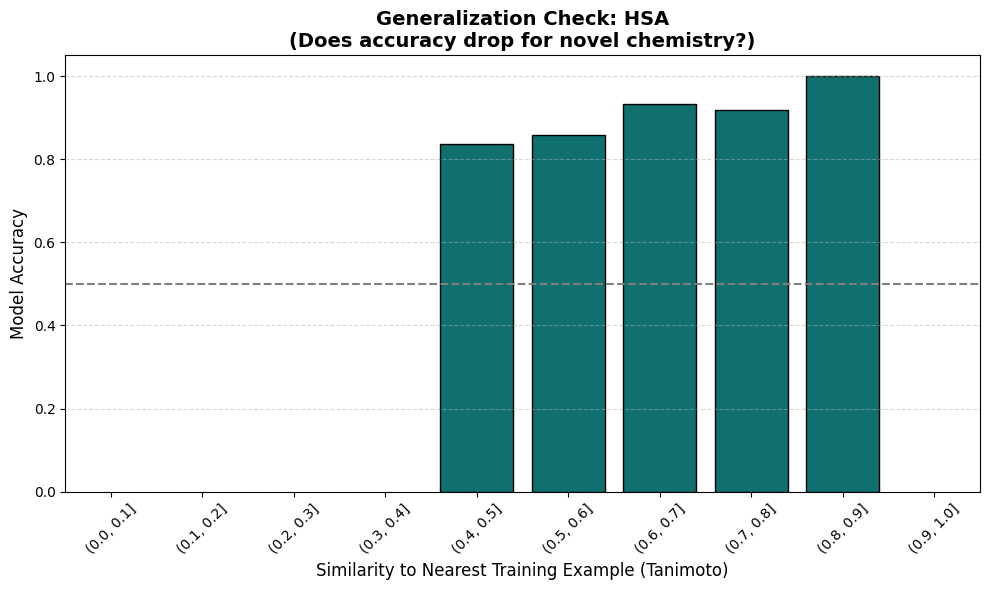

Interpretation:
- RIGHT side of plot = Memorization Zone (Easy).
- LEFT side of plot = Generalization Zone (Hard/Novel).
- If the bars stay high on the LEFT, your model is scientifically robust.


In [85]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from rdkit import Chem, DataStructs
from rdkit.Chem import AllChem
from tqdm.auto import tqdm

def plot_generalization_test(train_df, test_df, y_true, y_prob, target_index=1, sample_n=2000):
    """
    Plots Accuracy vs. Max Tanimoto Similarity to the Training Set.
    Proves the model isn't just memorizing.
    """
    target_name = CFG.targets[target_index]
    print(f"Running Generalization Test for {target_name}...")
    
    # 1. Generate Fingerprints for a SAMPLE of the Training Set (to save time)
    # We use a random subset of 2000 training molecules as the "Reference Bank"
    train_sample = train_df.sample(n=min(len(train_df), sample_n), random_state=42)
    train_fps = [AllChem.GetMorganFingerprintAsBitVect(Chem.MolFromSmiles(s), 2, nBits=1024) 
                 for s in tqdm(train_sample['molecule_smiles'], desc="Encoding Train Bank")]
    
    # 2. Process Test Set (Subset for speed)
    test_subset_idx = np.random.choice(len(test_df), size=min(len(test_df), 1000), replace=False)
    test_fps = []
    max_sims = []
    correct_preds = []
    
    # Binary predictions
    preds = (y_prob[:, target_index] > 0.5).astype(int)
    
    print("Calculating similarity to training set (this takes a moment)...")
    for idx in tqdm(test_subset_idx, desc="Checking Test Mols"):
        s = test_df.iloc[idx]['molecule_smiles']
        mol = Chem.MolFromSmiles(s)
        if mol:
            fp = AllChem.GetMorganFingerprintAsBitVect(mol, 2, nBits=1024)
            
            # Find the max similarity to ANY training molecule in our bank
            sims = DataStructs.BulkTanimotoSimilarity(fp, train_fps)
            max_sim = max(sims)
            
            max_sims.append(max_sim)
            # Did the model get it right?
            is_correct = 1 if preds[idx] == y_true[idx, target_index] else 0
            correct_preds.append(is_correct)
            
    # 3. Create DataFrame
    df_gen = pd.DataFrame({
        'Max_Similarity': max_sims,
        'Correct': correct_preds
    })
    
    # Binning the similarity (e.g., 0.3-0.4, 0.4-0.5, etc.)
    df_gen['Sim_Bin'] = pd.cut(df_gen['Max_Similarity'], bins=np.arange(0, 1.1, 0.1))
    
    # Calculate Mean Accuracy per Bin
    bin_stats = df_gen.groupby('Sim_Bin')['Correct'].mean().reset_index()
    
    # 4. Plot
    plt.figure(figsize=(10, 6))
    sns.barplot(data=bin_stats, x='Sim_Bin', y='Correct', color='teal', edgecolor='black')
    
    plt.title(f"Generalization Check: {target_name}\n(Does accuracy drop for novel chemistry?)", fontsize=14, fontweight='bold')
    plt.xlabel("Similarity to Nearest Training Example (Tanimoto)", fontsize=12)
    plt.ylabel("Model Accuracy", fontsize=12)
    plt.ylim(0, 1.05)
    plt.axhline(0.5, linestyle='--', color='gray', label='Random Guess')
    plt.xticks(rotation=45)
    plt.grid(axis='y', linestyle='--', alpha=0.5)
    
    plt.tight_layout()
    plt.show()
    
    print("Interpretation:")
    print("- RIGHT side of plot = Memorization Zone (Easy).")
    print("- LEFT side of plot = Generalization Zone (Hard/Novel).")
    print("- If the bars stay high on the LEFT, your model is scientifically robust.")

# Run the test (Assuming 'train_df' is still in memory from your notebook)
# If train_df is not available, you might need to reload it or skip this.
if 'train_df' in locals():
    plot_generalization_test(train_df, test_df, y_te, te_prob, target_index=1)
else:
    print("Please ensure 'train_df' is loaded to run this comparison.")


--- Scanning Target: BRD4 ---
  Encoding fingerprints...
  Checking similarity threshold > 0.85...
  Checking similarity threshold > 0.8...
  Checking similarity threshold > 0.75...
  SUCCESS: Found 2 cliffs at threshold 0.75!


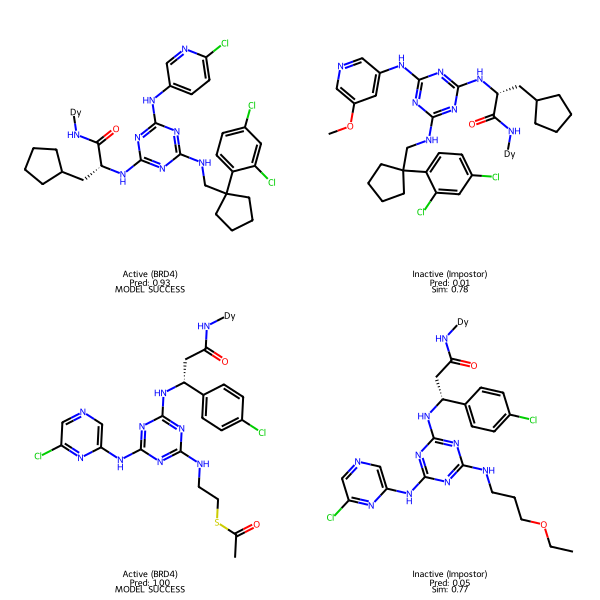

In [95]:
import matplotlib.pyplot as plt
from rdkit import Chem
from rdkit.Chem import Draw
from rdkit.Chem import AllChem, DataStructs
import numpy as np

def visualize_activity_cliffs_robust(test_df, y_true, y_prob, targets):
    """
    Robust version: Scans ALL targets and dynamically lowers similarity threshold
    until it finds valid Activity Cliffs to visualize.
    """
    
    # Try these thresholds in order
    thresholds = [0.85, 0.80, 0.75, 0.70]
    
    for target_index, target_name in enumerate(targets):
        print(f"\n--- Scanning Target: {target_name} ---")
        
        # Get indices
        actives_idx = np.where(y_true[:, target_index] == 1)[0]
        inactives_idx = np.where(y_true[:, target_index] == 0)[0]
        
        if len(actives_idx) < 5 or len(inactives_idx) < 5:
            print("  Skipping: Not enough active/inactive samples.")
            continue
            
        # Downsample for speed (but keep enough to find matches)
        if len(inactives_idx) > 3000: inactives_idx = np.random.choice(inactives_idx, 3000, replace=False)
        if len(actives_idx) > 1000: actives_idx = np.random.choice(actives_idx, 1000, replace=False)
        
        # Generate FPs
        print("  Encoding fingerprints...")
        active_data = [] # (fp, original_index)
        for i in actives_idx:
            m = Chem.MolFromSmiles(test_df.iloc[i]['molecule_smiles'])
            if m: active_data.append((AllChem.GetMorganFingerprintAsBitVect(m, 2, nBits=1024), i))
                
        inactive_data = []
        for i in inactives_idx:
            m = Chem.MolFromSmiles(test_df.iloc[i]['molecule_smiles'])
            if m: inactive_data.append((AllChem.GetMorganFingerprintAsBitVect(m, 2, nBits=1024), i))
        
        # Search with decreasing strictness
        for thresh in thresholds:
            print(f"  Checking similarity threshold > {thresh}...")
            cliffs = []
            
            # Extract FPs for bulk comparison
            act_fps = [x[0] for x in active_data]
            inact_fps = [x[0] for x in inactive_data]
            
            for i, fp_act in enumerate(act_fps):
                # Bulk similarity search
                sims = DataStructs.BulkTanimotoSimilarity(fp_act, inact_fps)
                
                for j, sim in enumerate(sims):
                    if sim > thresh:
                        # Found a pair!
                        act_idx = active_data[i][1]
                        inact_idx = inactive_data[j][1]
                        cliffs.append((act_idx, inact_idx, sim))
                        
                        # Stop if we have enough for this threshold
                        if len(cliffs) >= 4: break
                if len(cliffs) >= 4: break
            
            # If we found at least 2 pairs, PLOT THEM and STOP
            if len(cliffs) >= 2:
                print(f"  SUCCESS: Found {len(cliffs)} cliffs at threshold {thresh}!")
                
                mols = []
                legends = []
                
                for (idx_act, idx_inact, sim) in cliffs:
                    # Get Data
                    prob_act = y_prob[idx_act, target_index]
                    prob_inact = y_prob[idx_inact, target_index]
                    
                    # Determine success
                    # We want Active > 0.5 and Inactive < 0.5
                    is_success = (prob_act > 0.5) and (prob_inact < 0.5)
                    status_str = "MODEL SUCCESS" if is_success else "MODEL FAILED"
                    
                    # Active Info
                    mols.append(Chem.MolFromSmiles(test_df.iloc[idx_act]['molecule_smiles']))
                    legends.append(f"Active ({target_name})\nPred: {prob_act:.2f}\n{status_str}")
                    
                    # Inactive Info
                    mols.append(Chem.MolFromSmiles(test_df.iloc[idx_inact]['molecule_smiles']))
                    legends.append(f"Inactive (Impostor)\nPred: {prob_inact:.2f}\nSim: {sim:.2f}")

                # Plot grid
                img = Draw.MolsToGridImage(mols, molsPerRow=2, subImgSize=(300, 300), 
                                           legends=legends, useSVG=False)
                display(img)
                return # Exit function completely after one successful plot
            
    print("\n[Warning] No activity cliffs found even at lowest threshold. Your test set might be too small or chemically diverse.")

# Run the robust version
visualize_activity_cliffs_robust(test_df, y_te, te_prob, CFG.targets)


--- Scanning Target: BRD4 ---
  Encoding fingerprints...
  Checking similarity threshold > 0.85...
  Checking similarity threshold > 0.8...
  Checking similarity threshold > 0.75...
  Checking similarity threshold > 0.7...
  SUCCESS: Found 4 cliffs at threshold 0.7!


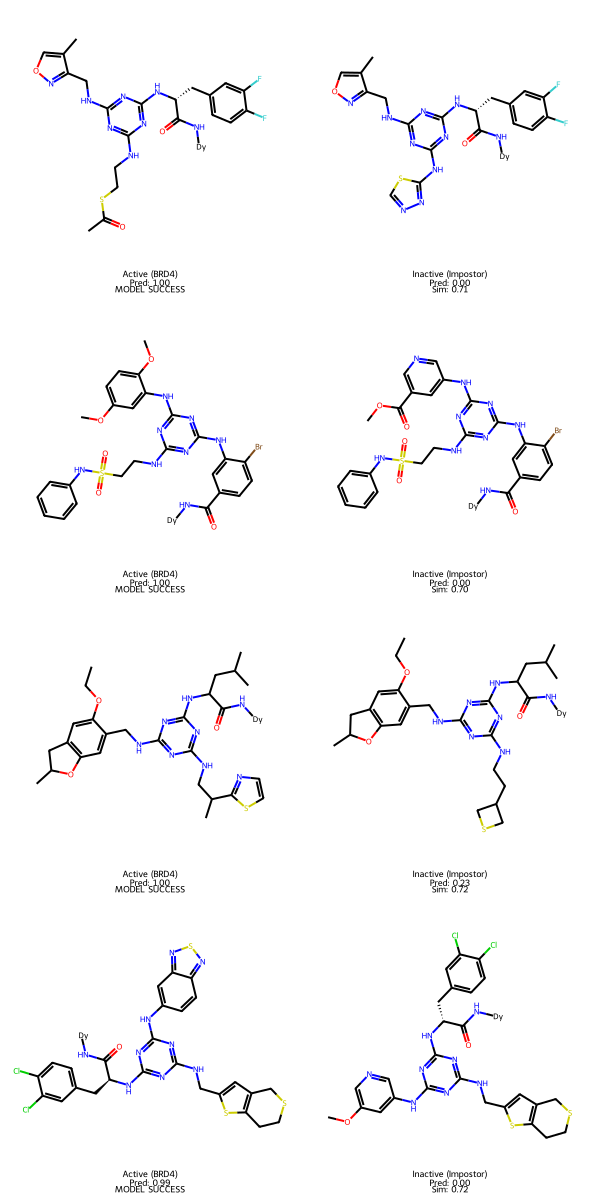

In [96]:
import matplotlib.pyplot as plt
from rdkit import Chem
from rdkit.Chem import Draw
from rdkit.Chem import AllChem, DataStructs
import numpy as np

def visualize_activity_cliffs_robust(test_df, y_true, y_prob, targets):
    """
    Robust version: Scans ALL targets and dynamically lowers similarity threshold
    until it finds valid Activity Cliffs to visualize.
    """
    
    # Try these thresholds in order
    thresholds = [0.85, 0.80, 0.75, 0.70]
    
    for target_index, target_name in enumerate(targets):
        print(f"\n--- Scanning Target: {target_name} ---")
        
        # Get indices
        actives_idx = np.where(y_true[:, target_index] == 1)[0]
        inactives_idx = np.where(y_true[:, target_index] == 0)[0]
        
        if len(actives_idx) < 5 or len(inactives_idx) < 5:
            print("  Skipping: Not enough active/inactive samples.")
            continue
            
        # Downsample for speed (but keep enough to find matches)
        if len(inactives_idx) > 3000: inactives_idx = np.random.choice(inactives_idx, 3000, replace=False)
        if len(actives_idx) > 1000: actives_idx = np.random.choice(actives_idx, 1000, replace=False)
        
        # Generate FPs
        print("  Encoding fingerprints...")
        active_data = [] # (fp, original_index)
        for i in actives_idx:
            m = Chem.MolFromSmiles(test_df.iloc[i]['molecule_smiles'])
            if m: active_data.append((AllChem.GetMorganFingerprintAsBitVect(m, 2, nBits=1024), i))
                
        inactive_data = []
        for i in inactives_idx:
            m = Chem.MolFromSmiles(test_df.iloc[i]['molecule_smiles'])
            if m: inactive_data.append((AllChem.GetMorganFingerprintAsBitVect(m, 2, nBits=1024), i))
        
        # Search with decreasing strictness
        for thresh in thresholds:
            print(f"  Checking similarity threshold > {thresh}...")
            cliffs = []
            
            # Extract FPs for bulk comparison
            act_fps = [x[0] for x in active_data]
            inact_fps = [x[0] for x in inactive_data]
            
            for i, fp_act in enumerate(act_fps):
                # Bulk similarity search
                sims = DataStructs.BulkTanimotoSimilarity(fp_act, inact_fps)
                
                for j, sim in enumerate(sims):
                    if sim > thresh:
                        # Found a pair!
                        act_idx = active_data[i][1]
                        inact_idx = inactive_data[j][1]
                        cliffs.append((act_idx, inact_idx, sim))
                        
                        # Stop if we have enough for this threshold
                        if len(cliffs) >= 4: break
                if len(cliffs) >= 4: break
            
            # If we found at least 2 pairs, PLOT THEM and STOP
            if len(cliffs) >= 2:
                print(f"  SUCCESS: Found {len(cliffs)} cliffs at threshold {thresh}!")
                
                mols = []
                legends = []
                
                for (idx_act, idx_inact, sim) in cliffs:
                    # Get Data
                    prob_act = y_prob[idx_act, target_index]
                    prob_inact = y_prob[idx_inact, target_index]
                    
                    # Determine success
                    # We want Active > 0.5 and Inactive < 0.5
                    is_success = (prob_act > 0.5) and (prob_inact < 0.5)
                    status_str = "MODEL SUCCESS" if is_success else "MODEL FAILED"
                    
                    # Active Info
                    mols.append(Chem.MolFromSmiles(test_df.iloc[idx_act]['molecule_smiles']))
                    legends.append(f"Active ({target_name})\nPred: {prob_act:.2f}\n{status_str}")
                    
                    # Inactive Info
                    mols.append(Chem.MolFromSmiles(test_df.iloc[idx_inact]['molecule_smiles']))
                    legends.append(f"Inactive (Impostor)\nPred: {prob_inact:.2f}\nSim: {sim:.2f}")

                # Plot grid
                img = Draw.MolsToGridImage(mols, molsPerRow=2, subImgSize=(300, 300), 
                                           legends=legends, useSVG=False)
                display(img)
                return # Exit function completely after one successful plot
            
    print("\n[Warning] No activity cliffs found even at lowest threshold. Your test set might be too small or chemically diverse.")

# Run the robust version
visualize_activity_cliffs_robust(test_df, y_te, te_prob, CFG.targets)


--- Scanning Target: BRD4 ---
  Encoding fingerprints...
  Checking similarity threshold > 0.85...
  Checking similarity threshold > 0.8...
  Checking similarity threshold > 0.75...
  Checking similarity threshold > 0.7...
  SUCCESS: Found 4 cliffs at threshold 0.7!


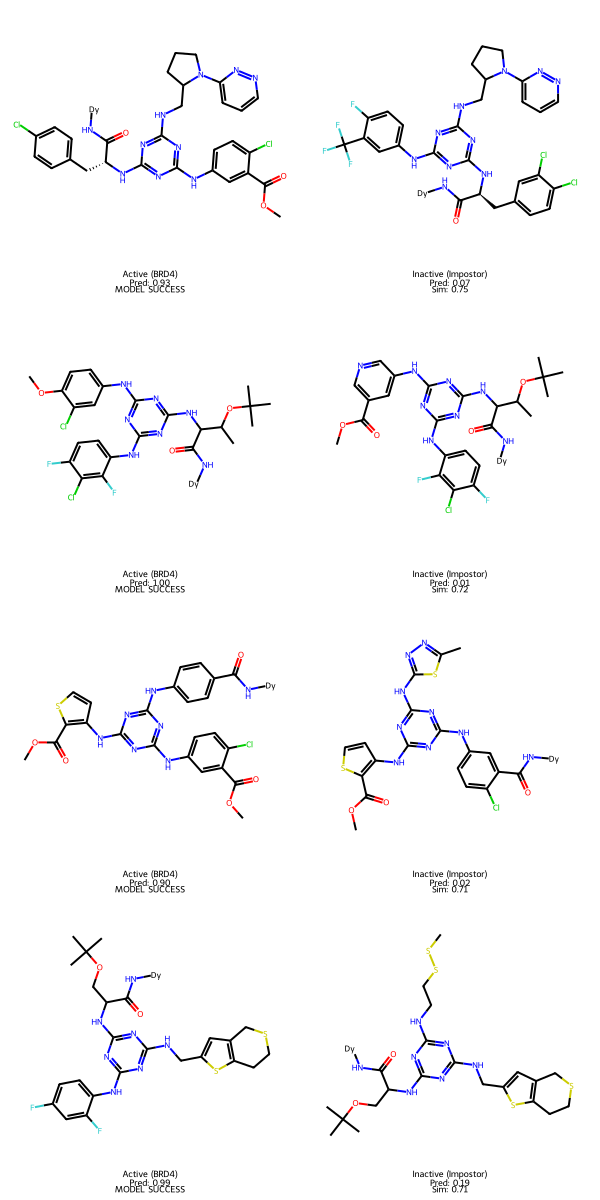

In [97]:
import matplotlib.pyplot as plt
from rdkit import Chem
from rdkit.Chem import Draw
from rdkit.Chem import AllChem, DataStructs
import numpy as np

def visualize_activity_cliffs_robust(test_df, y_true, y_prob, targets):
    """
    Robust version: Scans ALL targets and dynamically lowers similarity threshold
    until it finds valid Activity Cliffs to visualize.
    """
    
    # Try these thresholds in order
    thresholds = [0.85, 0.80, 0.75, 0.70]
    
    for target_index, target_name in enumerate(targets):
        print(f"\n--- Scanning Target: {target_name} ---")
        
        # Get indices
        actives_idx = np.where(y_true[:, target_index] == 1)[0]
        inactives_idx = np.where(y_true[:, target_index] == 0)[0]
        
        if len(actives_idx) < 5 or len(inactives_idx) < 5:
            print("  Skipping: Not enough active/inactive samples.")
            continue
            
        # Downsample for speed (but keep enough to find matches)
        if len(inactives_idx) > 3000: inactives_idx = np.random.choice(inactives_idx, 3000, replace=False)
        if len(actives_idx) > 1000: actives_idx = np.random.choice(actives_idx, 1000, replace=False)
        
        # Generate FPs
        print("  Encoding fingerprints...")
        active_data = [] # (fp, original_index)
        for i in actives_idx:
            m = Chem.MolFromSmiles(test_df.iloc[i]['molecule_smiles'])
            if m: active_data.append((AllChem.GetMorganFingerprintAsBitVect(m, 2, nBits=1024), i))
                
        inactive_data = []
        for i in inactives_idx:
            m = Chem.MolFromSmiles(test_df.iloc[i]['molecule_smiles'])
            if m: inactive_data.append((AllChem.GetMorganFingerprintAsBitVect(m, 2, nBits=1024), i))
        
        # Search with decreasing strictness
        for thresh in thresholds:
            print(f"  Checking similarity threshold > {thresh}...")
            cliffs = []
            
            # Extract FPs for bulk comparison
            act_fps = [x[0] for x in active_data]
            inact_fps = [x[0] for x in inactive_data]
            
            for i, fp_act in enumerate(act_fps):
                # Bulk similarity search
                sims = DataStructs.BulkTanimotoSimilarity(fp_act, inact_fps)
                
                for j, sim in enumerate(sims):
                    if sim > thresh:
                        # Found a pair!
                        act_idx = active_data[i][1]
                        inact_idx = inactive_data[j][1]
                        cliffs.append((act_idx, inact_idx, sim))
                        
                        # Stop if we have enough for this threshold
                        if len(cliffs) >= 4: break
                if len(cliffs) >= 4: break
            
            # If we found at least 2 pairs, PLOT THEM and STOP
            if len(cliffs) >= 2:
                print(f"  SUCCESS: Found {len(cliffs)} cliffs at threshold {thresh}!")
                
                mols = []
                legends = []
                
                for (idx_act, idx_inact, sim) in cliffs:
                    # Get Data
                    prob_act = y_prob[idx_act, target_index]
                    prob_inact = y_prob[idx_inact, target_index]
                    
                    # Determine success
                    # We want Active > 0.5 and Inactive < 0.5
                    is_success = (prob_act > 0.5) and (prob_inact < 0.5)
                    status_str = "MODEL SUCCESS" if is_success else "MODEL FAILED"
                    
                    # Active Info
                    mols.append(Chem.MolFromSmiles(test_df.iloc[idx_act]['molecule_smiles']))
                    legends.append(f"Active ({target_name})\nPred: {prob_act:.2f}\n{status_str}")
                    
                    # Inactive Info
                    mols.append(Chem.MolFromSmiles(test_df.iloc[idx_inact]['molecule_smiles']))
                    legends.append(f"Inactive (Impostor)\nPred: {prob_inact:.2f}\nSim: {sim:.2f}")

                # Plot grid
                img = Draw.MolsToGridImage(mols, molsPerRow=2, subImgSize=(300, 300), 
                                           legends=legends, useSVG=False)
                display(img)
                return # Exit function completely after one successful plot
            
    print("\n[Warning] No activity cliffs found even at lowest threshold. Your test set might be too small or chemically diverse.")

# Run the robust version
visualize_activity_cliffs_robust(test_df, y_te, te_prob, CFG.targets)

Running t-SNE dimensionality reduction...


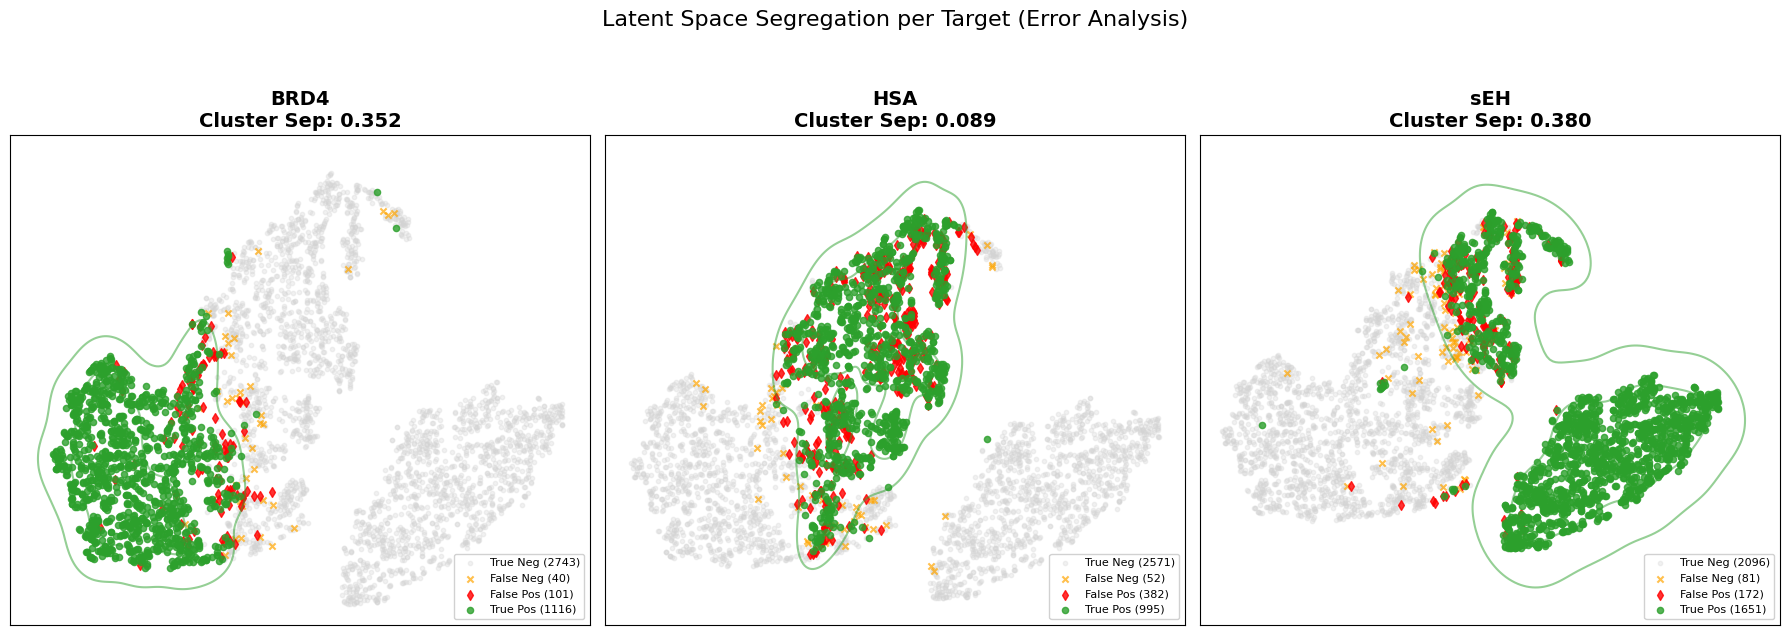

In [98]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.manifold import TSNE
from sklearn.metrics import silhouette_score

def plot_detailed_target_clustering(embeddings, y_true, y_prob, targets, max_samples=4000):
    """
    Generates high-detail t-SNE plots for each target, distinguishing between
    True Positives, False Positives (Errors), and True Negatives.
    """
    n_targets = len(targets)
    fig, axes = plt.subplots(1, n_targets, figsize=(6 * n_targets, 6))
    
    # If only 1 target, wrap axis in list
    if n_targets == 1: axes = [axes]
    
    print("Running t-SNE dimensionality reduction...")
    # 1. Run t-SNE on a subset first (Computing t-SNE on full test set is too slow)
    # We take a stratified sample
    if len(embeddings) > max_samples:
        indices = np.random.choice(len(embeddings), max_samples, replace=False)
        X_sub = embeddings[indices]
        y_true_sub = y_true[indices]
        y_prob_sub = y_prob[indices]
    else:
        X_sub = embeddings
        y_true_sub = y_true
        y_prob_sub = y_prob

    # Compute t-SNE once for the shared latent space
    tsne = TSNE(n_components=2, perplexity=35, init='pca', learning_rate='auto', random_state=42)
    X_embedded = tsne.fit_transform(X_sub)
    
    # 2. Plot for each target
    for i, target in enumerate(targets):
        ax = axes[i]
        
        # Get labels and probs for this target
        y_t = y_true_sub[:, i]
        y_p = (y_prob_sub[:, i] > 0.5).astype(int) # Threshold at 0.5
        
        # Define Categories
        # TN: True 0, Pred 0
        mask_tn = (y_t == 0) & (y_p == 0)
        # TP: True 1, Pred 1
        mask_tp = (y_t == 1) & (y_p == 1)
        # FP: True 0, Pred 1 (Model Hallucination)
        mask_fp = (y_t == 0) & (y_p == 1)
        # FN: True 1, Pred 0 (Missed Drug)
        mask_fn = (y_t == 1) & (y_p == 0)
        
        # Calculate Cluster Separation Score (Silhouette) for Actives vs Inactives
        # Only calc if we have both classes
        if len(np.unique(y_t)) > 1:
            sil_score = silhouette_score(X_embedded, y_t)
            score_text = f"Cluster Sep: {sil_score:.3f}"
        else:
            score_text = "Cluster Sep: N/A"

        # --- PLOTTING ORDER MATTERS ---
        # 1. Background (TN) - Gray, faint
        ax.scatter(X_embedded[mask_tn, 0], X_embedded[mask_tn, 1], 
                   c='lightgray', s=10, alpha=0.3, label=f'True Neg ({np.sum(mask_tn)})')
        
        # 2. Missed (FN) - Orange, medium
        ax.scatter(X_embedded[mask_fn, 0], X_embedded[mask_fn, 1], 
                   c='orange', s=20, alpha=0.7, marker='x', label=f'False Neg ({np.sum(mask_fn)})')
        
        # 3. Errors (FP) - Red, bold (Visualizing "Hallucinations")
        ax.scatter(X_embedded[mask_fp, 0], X_embedded[mask_fp, 1], 
                   c='red', s=25, alpha=0.8, marker='d', label=f'False Pos ({np.sum(mask_fp)})')
        
        # 4. Hits (TP) - Green, bold (Visualizing Success)
        ax.scatter(X_embedded[mask_tp, 0], X_embedded[mask_tp, 1], 
                   c='#2ca02c', s=20, alpha=0.8, label=f'True Pos ({np.sum(mask_tp)})')

        # Formatting
        ax.set_title(f"{target}\n{score_text}", fontsize=14, fontweight='bold')
        ax.set_xticks([])
        ax.set_yticks([])
        
        # Add a density contour for the True Positives to show the "Active Region"
        # (Optional but looks pro)
        if np.sum(mask_tp) > 5:
            sns.kdeplot(x=X_embedded[mask_tp, 0], y=X_embedded[mask_tp, 1], 
                        ax=ax, levels=3, color='#2ca02c', linewidths=1.5, alpha=0.5)

        # Legend at bottom
        ax.legend(loc='lower right', fontsize=8, framealpha=0.9)
        ax.grid(False)

    plt.suptitle("Latent Space Segregation per Target (Error Analysis)", fontsize=16, y=1.05)
    plt.tight_layout()
    plt.show()

# Run the detailed clustering
plot_detailed_target_clustering(te_fused, y_te, te_prob, CFG.targets)

Selecting 50000 random molecules for clustering...
Running t-SNE (this measures similarity)...


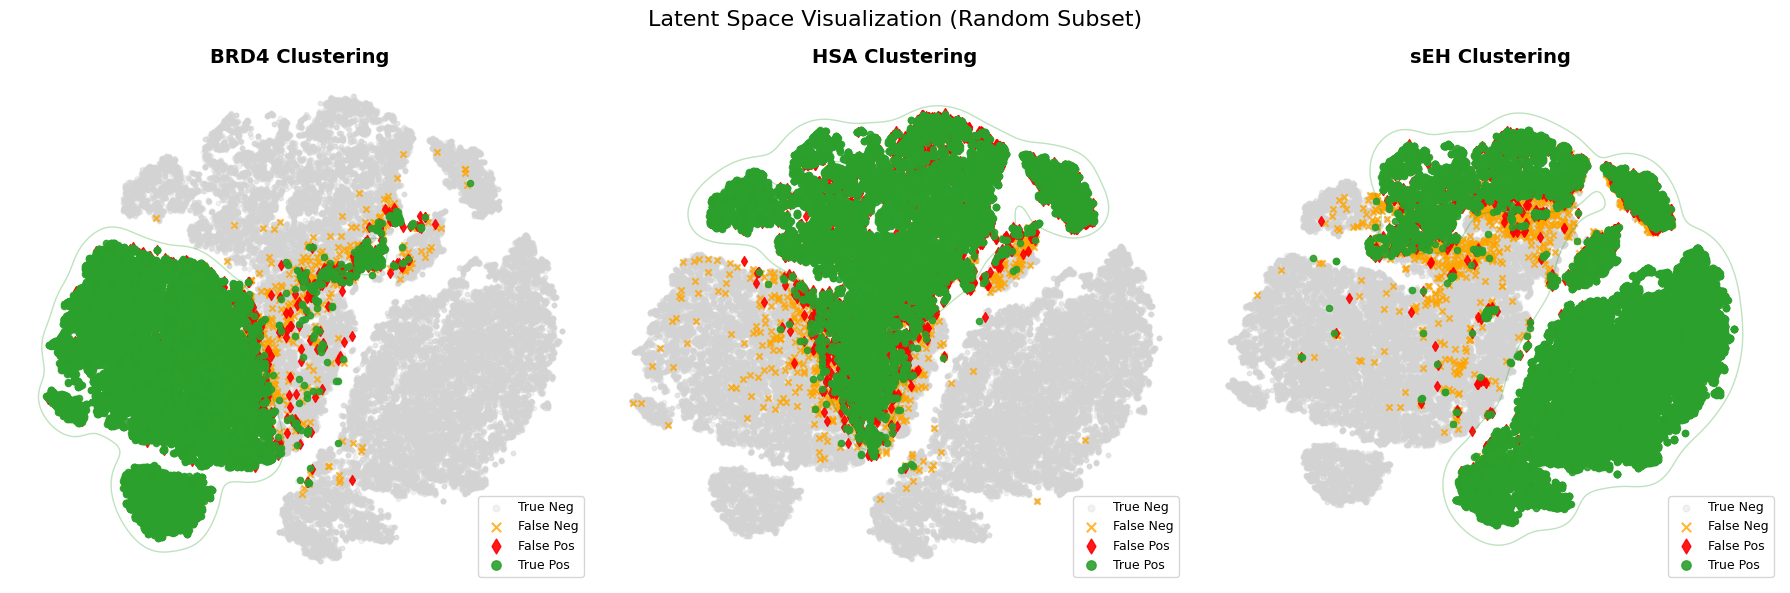

In [105]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.manifold import TSNE
from sklearn.metrics import silhouette_score

def plot_randomized_clustering(embeddings, y_true, y_prob, targets, n_samples=50000):
    """
    Picks a RANDOM subset of the test data and clusters it.
    Visualizes True Positives (Green), False Positives (Red), and background.
    """
    n_targets = len(targets)
    fig, axes = plt.subplots(1, n_targets, figsize=(6 * n_targets, 6))
    if n_targets == 1: axes = [axes]
    
    # --- 1. RANDOM SAMPLING ---
    print(f"Selecting {n_samples} random molecules for clustering...")
    if len(embeddings) > n_samples:
        # No fixed seed here -> purely random every time you run it
        indices = np.random.choice(len(embeddings), n_samples, replace=False)
        X_sub = embeddings[indices]
        y_true_sub = y_true[indices]
        y_prob_sub = y_prob[indices]
    else:
        X_sub = embeddings
        y_true_sub = y_true
        y_prob_sub = y_prob

    # --- 2. RUN t-SNE ---
    print("Running t-SNE (this measures similarity)...")
    # We use random initialization for variety
    tsne = TSNE(n_components=2, perplexity=30, init='pca', learning_rate='auto') 
    X_embedded = tsne.fit_transform(X_sub)
    
    # --- 3. PLOT EACH TARGET ---
    for i, target in enumerate(targets):
        ax = axes[i]
        
        # Data for this target
        y_t = y_true_sub[:, i]
        y_p = (y_prob_sub[:, i] > 0.5).astype(int)
        
        # Groups
        tn = (y_t == 0) & (y_p == 0) # Background (Gray)
        tp = (y_t == 1) & (y_p == 1) # Success (Green)
        fp = (y_t == 0) & (y_p == 1) # Hallucination (Red)
        fn = (y_t == 1) & (y_p == 0) # Missed (Orange)
        
        # Plotting (Order: TN -> FN -> FP -> TP)
        # 1. Background (TN)
        ax.scatter(X_embedded[tn, 0], X_embedded[tn, 1], c='lightgray', s=10, alpha=0.3, label='True Neg')
        
        # 2. Missed (FN)
        ax.scatter(X_embedded[fn, 0], X_embedded[fn, 1], c='orange', s=20, marker='x', alpha=0.8, label='False Neg')
        
        # 3. Errors (FP)
        ax.scatter(X_embedded[fp, 0], X_embedded[fp, 1], c='red', s=25, marker='d', alpha=0.9, label='False Pos')
        
        # 4. Hits (TP) 
        ax.scatter(X_embedded[tp, 0], X_embedded[tp, 1], c='#2ca02c', s=20, alpha=0.9, label='True Pos')
        
        # Add Density Contours for Actives (to see the "shape" of valid drugs)
        if np.sum(tp) > 5:
            try:
                sns.kdeplot(x=X_embedded[tp, 0], y=X_embedded[tp, 1], ax=ax, 
                            levels=3, color='#2ca02c', alpha=0.3, linewidths=1)
            except:
                pass # Skip KDE if data is too sparse

        ax.set_title(f"{target} Clustering", fontsize=14, fontweight='bold')
        ax.legend(loc='lower right', markerscale=1.5, fontsize=9)
        ax.axis('off') # Clean look

    plt.suptitle("Latent Space Visualization (Random Subset)", fontsize=16)
    plt.tight_layout()
    plt.show()

# Run it
plot_randomized_clustering(te_fused, y_te, te_prob, CFG.targets)

In [107]:
import graphviz
from graphviz import Digraph
import os

def generate_architecture_diagram(filename='model_architecture'):
    """
    Generates a publication-quality block diagram of the Hybrid methodology.
    """
    dot = Digraph(comment='Hybrid Model Architecture', format='png')
    dot.attr(rankdir='TB', nodesep='0.5', ranksep='0.5')
    
    # Global styles
    dot.attr('node', shape='box', style='filled', fillcolor='white', fontname='Helvetica', fontsize='10')
    dot.attr('edge', fontname='Helvetica', fontsize='9')

    # --- INPUTS ---
    with dot.subgraph(name='cluster_inputs') as c:
        c.attr(style='dashed', color='gray', label='Inputs')
        c.node('SMILES', 'SMILES String\n(Sequence)', shape='ellipse', fillcolor='#e1f5fe')
        c.node('FP', 'Morgan Fingerprints\n(2048-bit Vector)', shape='ellipse', fillcolor='#e1f5fe')
        c.node('BB', 'Building Block Indices\n(Integers)', shape='ellipse', fillcolor='#e1f5fe')

    # --- ENCODERS ---
    # Branch 1: Transformer
    dot.node('ChemBERTa', 'ChemBERTa Encoder\n(Pre-trained Transformer)', fillcolor='#fff9c4', height='0.8')
    dot.node('Pool', 'Attention Pooling\n(Weighted Mean)', fillcolor='#fff9c4')
    
    # Branch 2: Fingerprint
    dot.node('FP_Proj', 'Projection MLP\n(2048 -> 256)', fillcolor='#ffe0b2')
    
    # Branch 3: Building Blocks
    dot.node('BB_Embed', 'Embedding Lookup\n(Learnable)', fillcolor='#dcedc8')
    dot.node('BB_Agg', 'Average & Project', fillcolor='#dcedc8')

    # --- FUSION ---
    dot.node('Concat', 'Concatenation\n(Fusion Layer)', shape='diamond', fillcolor='#e0e0e0', height='0.6')
    dot.node('Dropout', 'Dropout (0.1)')
    
    # --- HEAD ---
    dot.node('Classifier', 'Classification Head\n(Linear -> Logits)', fillcolor='#ffccbc')
    dot.node('Output', 'Predictions\n(BRD4, HSA, sEH)', shape='doubleoctagon', fillcolor='#ffab91')

    # --- EDGES ---
    # Flow 1
    dot.edge('SMILES', 'ChemBERTa', label='Token IDs')
    dot.edge('ChemBERTa', 'Pool', label='Hidden States')
    dot.edge('Pool', 'Concat', label='Seq Features')

    # Flow 2
    dot.edge('FP', 'FP_Proj', label='Bit Vector')
    dot.edge('FP_Proj', 'Concat', label='Struct Features')

    # Flow 3
    dot.edge('BB', 'BB_Embed', label='Indices')
    dot.edge('BB_Embed', 'BB_Agg', label='Vectors')
    dot.edge('BB_Agg', 'Concat', label='Component Features')

    # Final Flow
    dot.edge('Concat', 'Dropout')
    dot.edge('Dropout', 'Classifier')
    dot.edge('Classifier', 'Output', label='Sigmoid')

    # Render
    try:
        output_path = dot.render(filename, view=True)
        print(f"Diagram saved to: {output_path}")
        display(dot)
    except Exception as e:
        print("Graphviz executable not found. Please install Graphviz or view the structure below.")
        print(dot.source)

# Run it
generate_architecture_diagram()

Graphviz executable not found. Please install Graphviz or view the structure below.
// Hybrid Model Architecture
digraph {
	nodesep=0.5 rankdir=TB ranksep=0.5
	node [fillcolor=white fontname=Helvetica fontsize=10 shape=box style=filled]
	edge [fontname=Helvetica fontsize=9]
	subgraph cluster_inputs {
		color=gray label=Inputs style=dashed
		SMILES [label="SMILES String
(Sequence)" fillcolor="#e1f5fe" shape=ellipse]
		FP [label="Morgan Fingerprints
(2048-bit Vector)" fillcolor="#e1f5fe" shape=ellipse]
		BB [label="Building Block Indices
(Integers)" fillcolor="#e1f5fe" shape=ellipse]
	}
	ChemBERTa [label="ChemBERTa Encoder
(Pre-trained Transformer)" fillcolor="#fff9c4" height=0.8]
	Pool [label="Attention Pooling
(Weighted Mean)" fillcolor="#fff9c4"]
	FP_Proj [label="Projection MLP
(2048 -> 256)" fillcolor="#ffe0b2"]
	BB_Embed [label="Embedding Lookup
(Learnable)" fillcolor="#dcedc8"]
	BB_Agg [label="Average & Project" fillcolor="#dcedc8"]
	Concat [label="Concatenation
(Fusion Layer)" fil